In [1]:
import h5py
import os

import sys
sys.path.append('../code')

import pandas as pd
import numpy as np
import pysam

from tqdm.notebook import tqdm
from preprocessing_tools import *

tqdm.pandas()


In [22]:
contexts = pd.read_csv('/Users/piotrradzinski/sc-cancer-sig-deconv/data/COSMIC/COSMIC_v3.4_SBS_GRCh38.txt', usecols=['Type'], sep='\t')
assembly = pd.read_json('/Users/piotrradzinski/sc-cancer-sig-deconv/data/ncbi_genome/ncbi_dataset/data/sequence_report.jsonl', lines=True)
chr_id = dict(zip(assembly['ucscStyleName'], assembly['refseqAccession']))
genome = pysam.FastaFile('/Users/piotrradzinski/sc-cancer-sig-deconv/data/ncbi_genome/ncbi_dataset/data/GCF_000001405.13/GCF_000001405.13_GRCh37_genomic.fna')

In [21]:
"""
Per-cell SNV calls from the MSK SPECTRUM scWGS release (SBMClone outputs).

Expected layout inside scWGS/sbmclone/<patient_id>/:

    alt_counts.npz   scipy.sparse matrix, cells x SNVs
    ref_counts.npz   scipy.sparse matrix, cells x SNVs
    cells.csv        row order of both matrices
    snvs.csv         column order of both matrices

Files downloaded through a browser into a single directory get a numeric
suffix, e.g. snvs(3).csv. Pass that number as `index` to pick one such group.

Returns a long-format table: one row per (cell, mutation) pair that has at
least `min_alt` variant-supporting reads.
"""

from pathlib import Path
import shutil

import numpy as np
import pandas as pd
from scipy import sparse

CELL_ID_CANDIDATES = ("cell_id", "brief_cell_id", "cell", "id")
SNV_EXTRA_COLUMNS = ("block_assignment",)


def _pick_cell_id_column(cells):
    for candidate in CELL_ID_CANDIDATES:
        if candidate in cells.columns:
            return candidate
    # fall back to the first column and let the caller notice
    return cells.columns[0]


def _resolve(folder, stem, extension, index=None):
    """Path to `stem.extension`, or `stem(index).extension` when index is given."""
    name = f"{stem}.{extension}" if index is None else f"{stem}({index}).{extension}"
    path = folder / name
    if not path.exists():
        raise FileNotFoundError(path)
    return path


def _infer_patient_id(cells, folder, index):
    if "patient_id" in cells.columns:
        values = pd.unique(cells["patient_id"].dropna())
        if len(values) == 1:
            return values[0]
    return folder.name if index is None else f"{folder.name}({index})"


def list_indices(folder):
    """Numeric suffixes present in `folder`, judged by the alt_counts files.

    A plain alt_counts.npz with no suffix is reported as None.
    """
    folder = Path(folder).expanduser()
    indices = []
    for path in folder.glob("alt_counts*.npz"):
        suffix = path.stem[len("alt_counts"):]
        if not suffix:
            indices.append(None)
        elif suffix.startswith("(") and suffix.endswith(")"):
            try:
                indices.append(int(suffix[1:-1]))
            except ValueError:
                pass
    return sorted(set(indices), key=lambda value: (value is not None, value))


def load_patient_snvs(folder, index=None, min_alt=1, patient_id=None):
    """Load one patient's files into a long DataFrame.

    Parameters
    ----------
    folder : str or Path
        Directory containing alt_counts.npz, ref_counts.npz, cells.csv, snvs.csv.
    index : int, optional
        Numeric suffix of a browser-downloaded file group, e.g. 3 selects
        alt_counts(3).npz together with cells(3).csv and snvs(3).csv.
    min_alt : int
        Minimum number of variant-supporting reads for a (cell, SNV) pair to be
        reported. 1 keeps everything the pipeline saw; 2 is markedly stricter
        and drops most single-read artefacts along with a lot of real signal.
    patient_id : str, optional
        Written into a `patient_id` column. Defaults to the folder name.
    """
    folder = Path(folder).expanduser()

    alt = sparse.load_npz(_resolve(folder, "alt_counts", "npz", index)).tocsr()
    ref = sparse.load_npz(_resolve(folder, "ref_counts", "npz", index)).tocsr()
    cells = pd.read_csv(_resolve(folder, "cells", "csv", index))
    snvs = pd.read_csv(_resolve(folder, "snvs", "csv", index))

    if patient_id is None:
        patient_id = _infer_patient_id(cells, folder, index)

    if alt.shape != ref.shape:
        raise ValueError(f"alt {alt.shape} and ref {ref.shape} disagree")
    if alt.shape != (len(cells), len(snvs)):
        raise ValueError(
            f"matrix is {alt.shape} but cells.csv has {len(cells)} rows "
            f"and snvs.csv has {len(snvs)} rows"
        )

    # non-zero entries of the alt matrix, as (row, column, value) triplets
    coo = alt.tocoo()
    keep = coo.data >= min_alt
    rows, cols, alt_counts = coo.row[keep], coo.col[keep], coo.data[keep]

    # depth at exactly those positions
    ref_counts = np.asarray(ref[rows, cols]).ravel()

    cell_id_col = _pick_cell_id_column(cells)

    out = pd.DataFrame(
        {
            "patient_id": patient_id,
            "cell_id": cells[cell_id_col].to_numpy()[rows],
            "chromosome": snvs["chromosome"].to_numpy()[cols],
            "position": snvs["position"].to_numpy()[cols],
            "ref": snvs["ref"].to_numpy()[cols],
            "alt": snvs["alt"].to_numpy()[cols],
            "alt_counts": alt_counts,
            "ref_counts": ref_counts,
        }
    )

    for column in SNV_EXTRA_COLUMNS:
        if column in snvs.columns:
            out[column] = snvs[column].to_numpy()[cols]

    out["total_counts"] = out["alt_counts"] + out["ref_counts"]
    out["vaf"] = out["alt_counts"] / out["total_counts"].replace(0, np.nan)

    return out


def load_cohort(root, patient_ids=None, min_alt=1, verbose=True):
    """Concatenate several patient folders found under `root`.

    `root` is the sbmclone directory; each subdirectory is treated as one
    patient unless `patient_ids` is given.
    """
    root = Path(root).expanduser()

    if patient_ids is None:
        folders = sorted(p for p in root.iterdir() if p.is_dir())
    else:
        folders = [root / pid for pid in patient_ids]

    frames = []
    for folder in folders:
        if not (folder / "alt_counts.npz").exists():
            if verbose:
                print(f"skipping {folder.name}: no alt_counts.npz")
            continue
        try:
            frame = load_patient_snvs(folder, min_alt=min_alt)
        except (ValueError, KeyError) as exc:
            if verbose:
                print(f"skipping {folder.name}: {exc}")
            continue
        if verbose:
            print(
                f"{folder.name}: {frame['cell_id'].nunique()} cells, "
                f"{len(frame)} calls"
            )
        frames.append(frame)

    if not frames:
        raise RuntimeError(f"no usable patient folders under {root}")

    return pd.concat(frames, ignore_index=True)


def load_indexed_folder(folder, indices=None, min_alt=1, verbose=True):
    """Concatenate every numbered file group sitting in one flat directory."""
    folder = Path(folder).expanduser()
    if indices is None:
        indices = list_indices(folder)

    frames = []
    for index in indices:
        try:
            frame = load_patient_snvs(folder, index=index, min_alt=min_alt)
        except (FileNotFoundError, ValueError, KeyError) as exc:
            if verbose:
                print(f"skipping index {index}: {exc}")
            continue
        if verbose:
            print(
                f"index {index} -> {frame['patient_id'].iloc[0]}: "
                f"{frame['cell_id'].nunique()} cells, {len(frame)} calls"
            )
        frames.append(frame)

    if not frames:
        raise RuntimeError(f"no usable file groups in {folder}")

    return pd.concat(frames, ignore_index=True)


def summarise(df):
    """Cells and calls per patient, plus median calls per cell."""
    per_cell = df.groupby(["patient_id", "cell_id"]).size()
    return pd.DataFrame(
        {
            "n_cells": df.groupby("patient_id")["cell_id"].nunique(),
            "n_calls": df.groupby("patient_id").size(),
            "median_calls_per_cell": per_cell.groupby("patient_id").median(),
        }
    ).sort_values("n_cells")


def _npz_shape(path):
    with np.load(path) as archive:
        return tuple(int(value) for value in archive["shape"])


def _csv_rows(path):
    with open(path, "r") as handle:
        return sum(1 for _ in handle) - 1


def discover_groups(folder):
    """Match alt/ref/cells/snvs files by shape rather than by filename number.

    Browser download counters can drift out of step between filenames. Shapes
    cannot: both matrices must be (n_cells, n_snvs), and those two numbers are
    the row counts of cells.csv and snvs.csv.
    """
    folder = Path(folder).expanduser()

    alt_shapes = {p: _npz_shape(p) for p in folder.glob("alt_counts*.npz")}
    ref_shapes = {p: _npz_shape(p) for p in folder.glob("ref_counts*.npz")}
    cell_rows = {p: _csv_rows(p) for p in folder.glob("cells*.csv")}
    snv_rows = {p: _csv_rows(p) for p in folder.glob("snvs*.csv")}

    records = []
    for alt_path, (n_cells, n_snvs) in sorted(alt_shapes.items()):
        refs = [p for p, s in ref_shapes.items() if s == (n_cells, n_snvs)]
        cells = [p for p, n in cell_rows.items() if n == n_cells]
        snvs = [p for p, n in snv_rows.items() if n == n_snvs]

        patient = None
        if len(cells) == 1:
            head = pd.read_csv(cells[0], nrows=1)
            if "patient_id" in head.columns:
                patient = head["patient_id"].iloc[0]

        def describe(matches):
            return matches[0].name if len(matches) == 1 else f"<{len(matches)} candidates>"

        records.append(
            {
                "alt": alt_path.name,
                "ref": describe(refs),
                "cells": describe(cells),
                "snvs": describe(snvs),
                "n_cells": n_cells,
                "n_snvs": n_snvs,
                "patient_id": patient,
                "unambiguous": len(refs) == len(cells) == len(snvs) == 1,
            }
        )

    return pd.DataFrame(records)


def organise_groups(folder, destination=None, move=False):
    """Copy (or move) each matched group into its own subdirectory.

    Files are given clean names, so afterwards load_patient_snvs works on each
    subdirectory with no `index` argument.
    """
    folder = Path(folder).expanduser()
    destination = Path(destination).expanduser() if destination else folder

    table = discover_groups(folder)
    action = shutil.move if move else shutil.copy2

    for _, row in table.iterrows():
        if not row["unambiguous"]:
            print(f"skipping {row['alt']}: ambiguous match, resolve by hand")
            continue

        label = row["patient_id"] or f"group_{row['n_cells']}x{row['n_snvs']}"
        target = destination / str(label)
        target.mkdir(parents=True, exist_ok=True)

        for source_name, clean_name in (
            (row["alt"], "alt_counts.npz"),
            (row["ref"], "ref_counts.npz"),
            (row["cells"], "cells.csv"),
            (row["snvs"], "snvs.csv"),
        ):
            action(folder / source_name, target / clean_name)

        print(f"{label}: {row['n_cells']} cells x {row['n_snvs']} SNVs")

    return table

In [37]:
dims = [
    "{}x{}".format(*_npz_shape(folder / "alt_counts.npz"))
    for folder in sorted(Path("/Users/piotrradzinski/sc-cancer-sig-deconv/data/matt").iterdir())
    if folder.is_dir() and (folder / "alt_counts.npz").exists()
]
print(dims)

['1028x8752', '1043x10407', '1057x27760', '1064x22483', '1111x17878', '125x2089', '1402x7667', '146x15418', '1530x5896', '1655x14700', '165x9328', '1785x13733', '1792x6500', '1872x11081', '2107x12901', '242x9320', '250x5178', '315x19085', '325x7290', '32x5739', '340x14183', '356x9811', '375x9475', '378x5523', '380x9837', '432x9816', '461x11109', '518x15854', '560x20237', '563x13728', '56x13065', '612x8498', '615x11910', '643x10053', '649x8330', '652x8585', '761x11619', '893x16605', '898x7332', '975x5856', '97x21882']


In [45]:
for dim in dims:
    df = load_patient_snvs(f'/Users/piotrradzinski/sc-cancer-sig-deconv/data/matt/group_{dim}')
    df = df[df['alt_counts'] > 0]
    df = df.rename(columns={'chromosome': 'chr', 'position': 'start'})
    df['sbs'] = df.progress_apply(get_sbs, axis=1, args=(genome, chr_id))

    table = pd.crosstab(df['cell_id'], df['sbs'])
    table = table.reindex(columns=contexts['Type'], fill_value=0) # Ensure all contexts are present as columns
    table.to_csv(f'/Users/piotrradzinski/sc-cancer-sig-deconv/data/mcpherson2025ongoing/mcpherson2025ongoing-OV{dim}.csv')

  0%|          | 0/379540 [00:00<?, ?it/s]

  0%|          | 0/334507 [00:00<?, ?it/s]

  0%|          | 0/649892 [00:00<?, ?it/s]

  0%|          | 0/829011 [00:00<?, ?it/s]

  0%|          | 0/691195 [00:00<?, ?it/s]

  0%|          | 0/10322 [00:00<?, ?it/s]

... (31 outputs left out)

  0%|          | 0/691040 [00:00<?, ?it/s]

  0%|          | 0/235278 [00:00<?, ?it/s]

  0%|          | 0/182235 [00:00<?, ?it/s]

  0%|          | 0/97463 [00:00<?, ?it/s]

In [46]:
import sys
import os

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.insert(0, os.path.join(REPO_ROOT, 'code'))

import numpy as np
import pandas as pd

from scunit import ScUnit
from analysis_tools import *

In [54]:
COSMIC_PATH = os.path.abspath(os.path.join(os.getcwd(), '../../data/COSMIC/COSMIC_v3.4_SBS_GRCh38.txt'))
cosmic = pd.read_csv(COSMIC_PATH, sep = '\t').set_index('Type').T

breast_sigs = ['SBS1', 'SBS2', 'SBS3', 'SBS5', 'SBS8', 'SBS9', 'SBS13', 'SBS17a', 'SBS17b', 'SBS18', 'SBS37', 'SBS40a', 'SBS40b', 'SBS40c', 'SBS41']
ovary_sigs = ['SBS1', 'SBS2', 'SBS3', 'SBS5', 'SBS8', 'SBS13', 'SBS18', 'SBS26', 'SBS35', 'SBS39', 'SBS40a', 'SBS40b', 'SBS40c', 'SBS41']

Loaded 1027 cells.
Mutations per cell:
	min:  79
	mean: 370
	max:  1372
Silhouette: 0.1597
DBCV: 0.0733


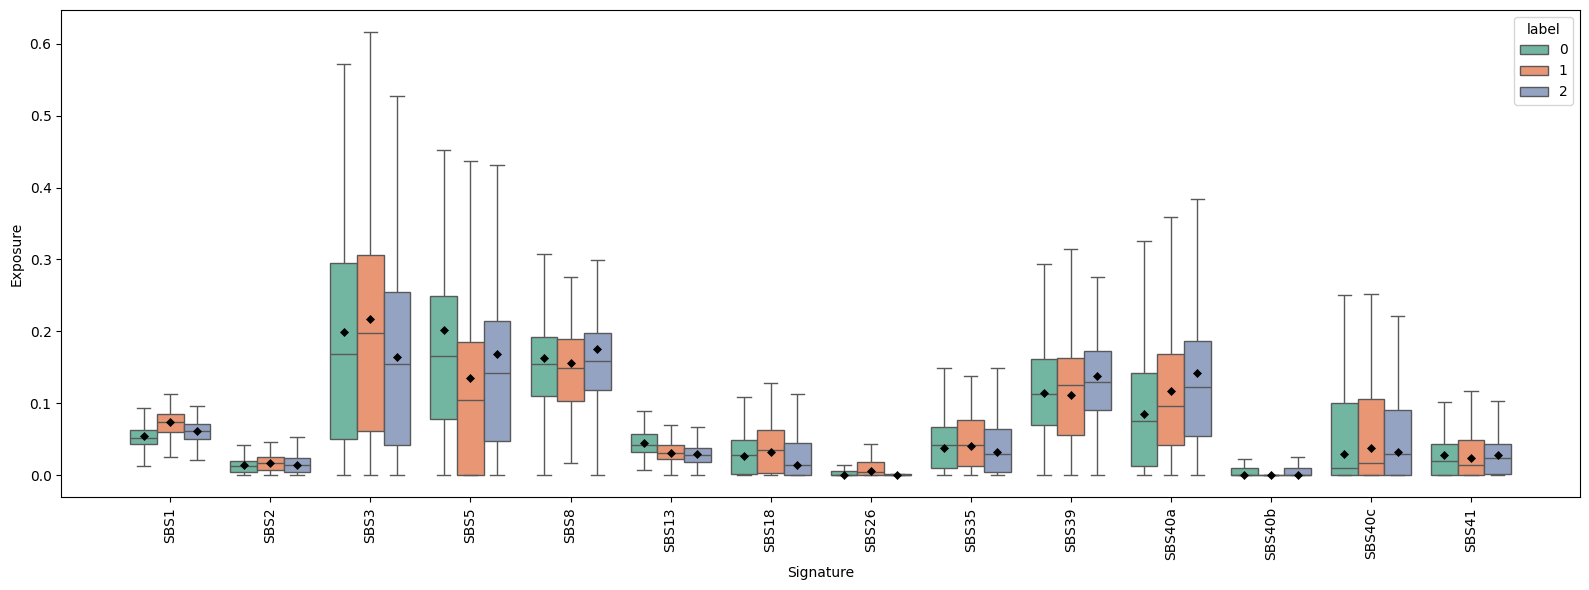

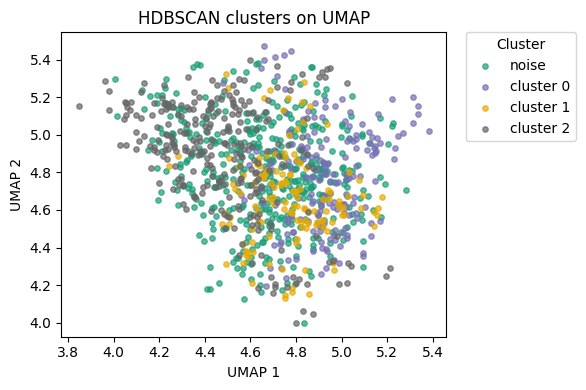

Loaded 1041 cells.
Mutations per cell:
	min:  72
	mean: 321
	max:  661
Silhouette: 0.2941
DBCV: 0.2972


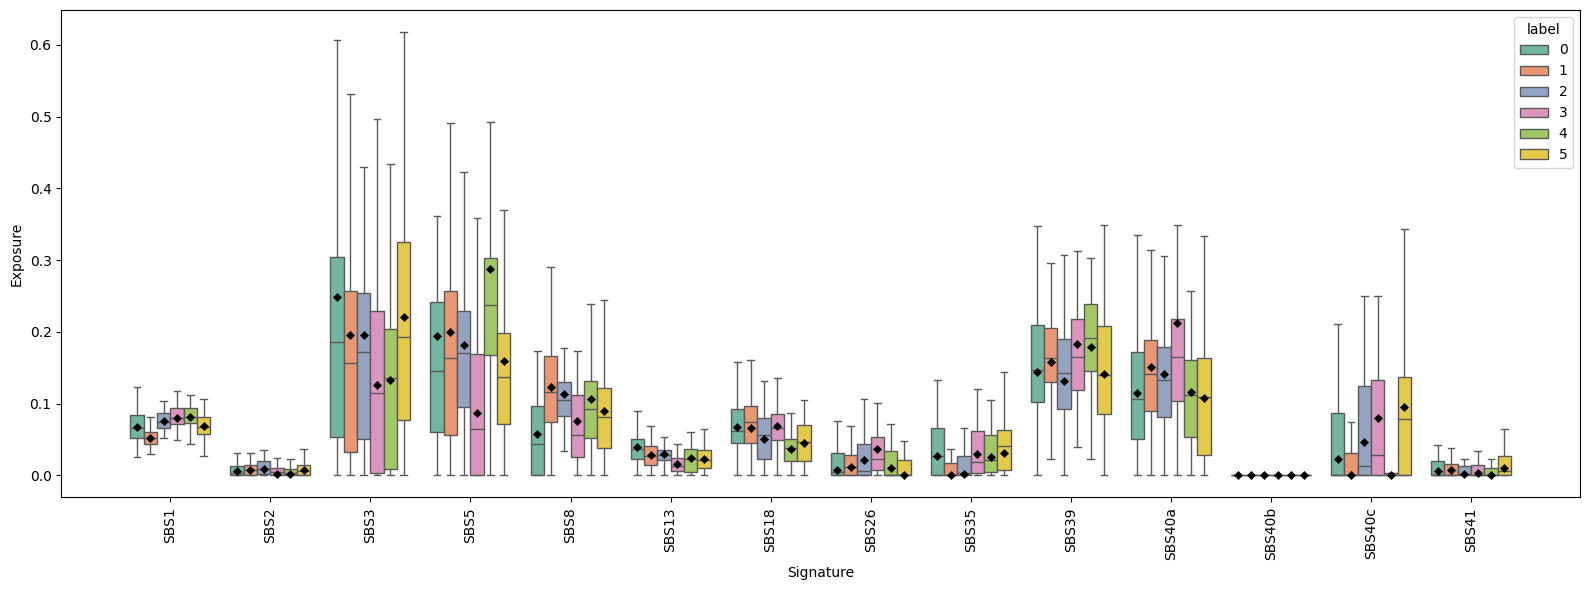

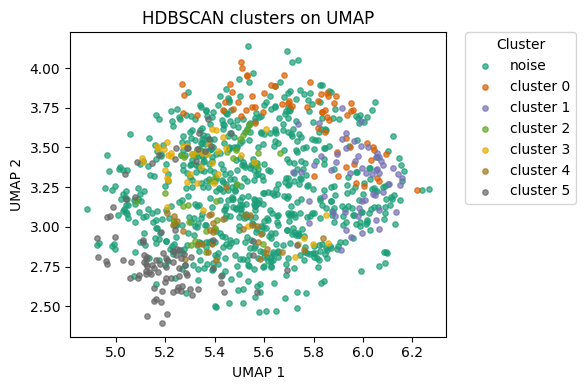

Loaded 1057 cells.
Mutations per cell:
	min:  84
	mean: 615
	max:  1451
Silhouette: 0.4050
DBCV: 0.1187


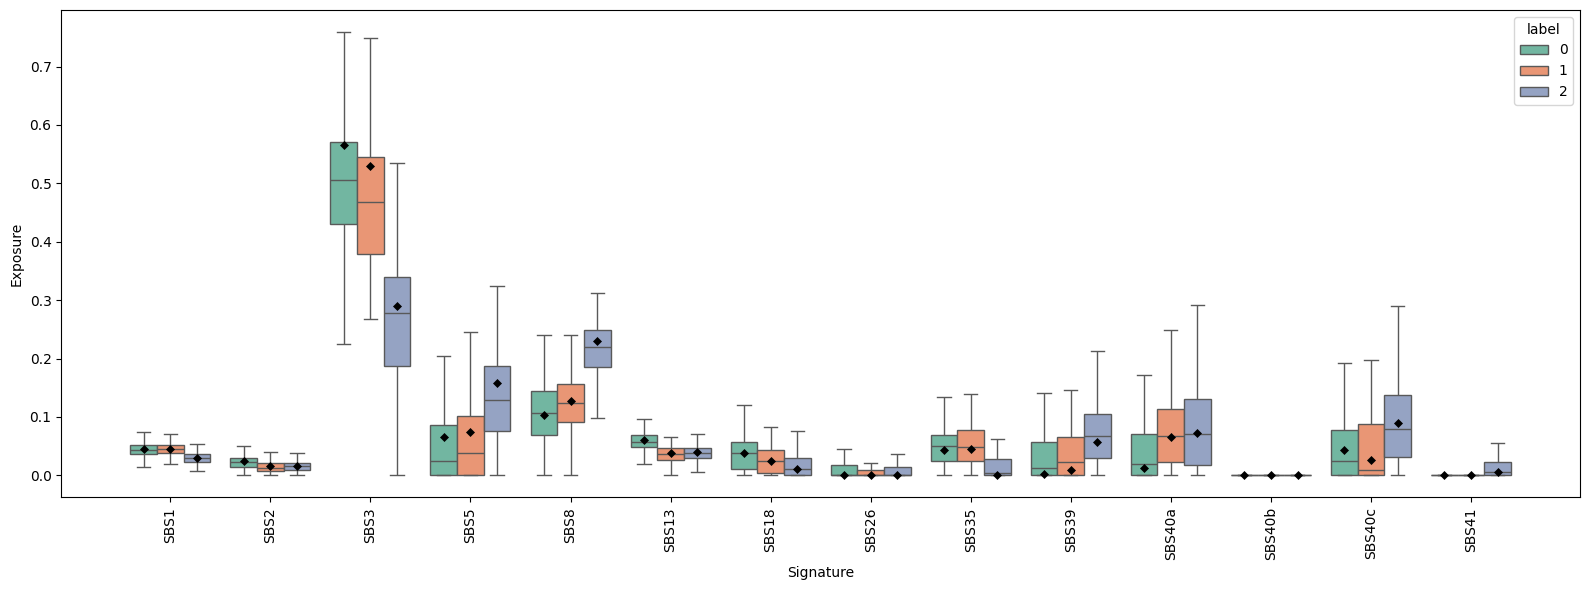

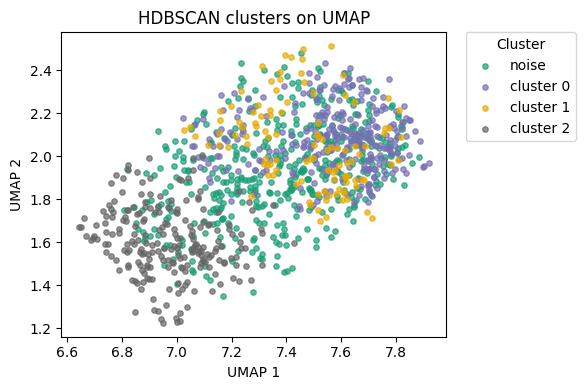

Loaded 1064 cells.
Mutations per cell:
	min:  124
	mean: 779
	max:  1850
Silhouette: 0.5276
DBCV: -0.0429


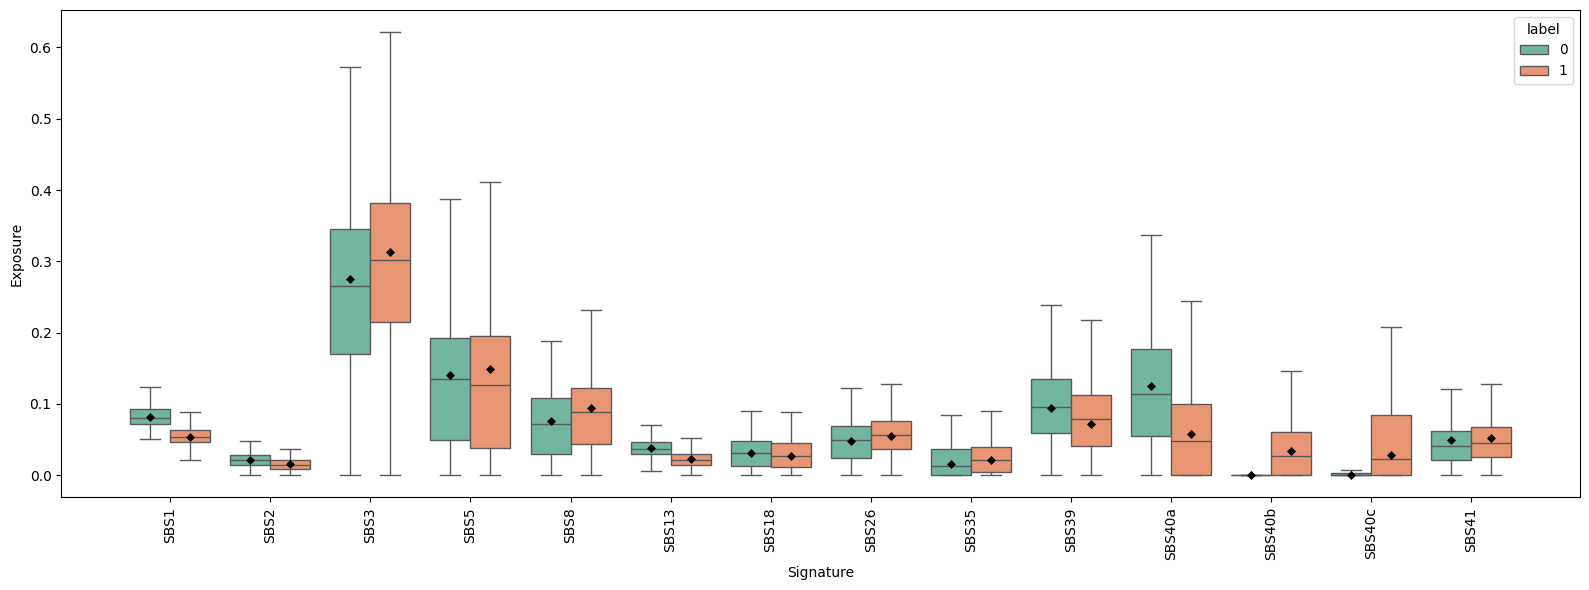

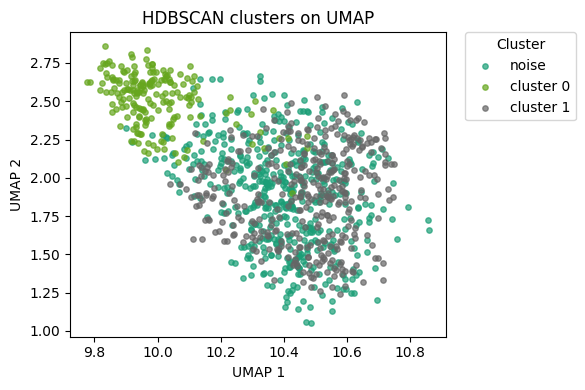

Loaded 1111 cells.
Mutations per cell:
	min:  140
	mean: 622
	max:  2076
Silhouette: 0.2497
DBCV: 0.2646


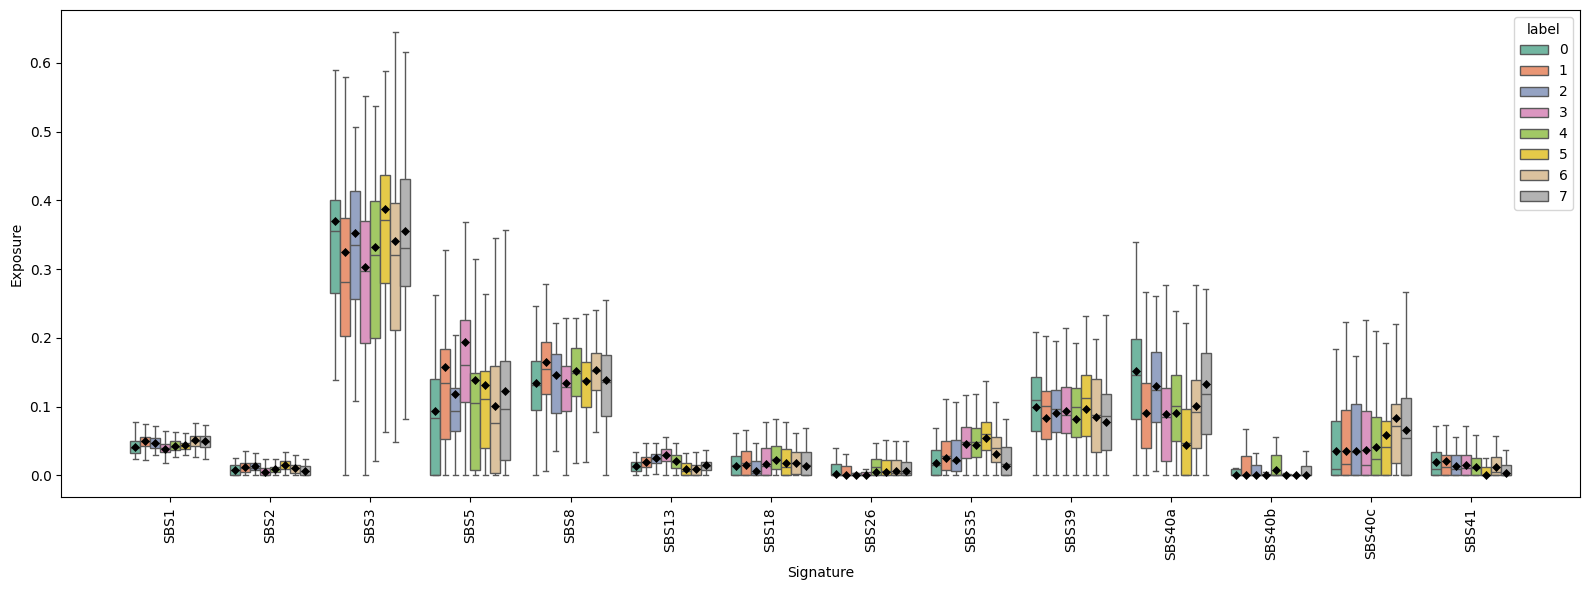

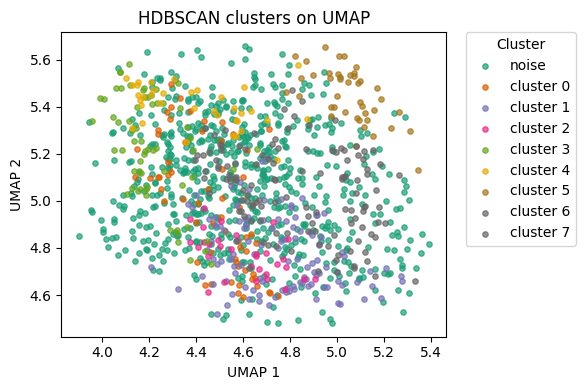

Loaded 121 cells.
Mutations per cell:
	min:  51
	mean: 84
	max:  189
Could not compute scores (too few clusters).


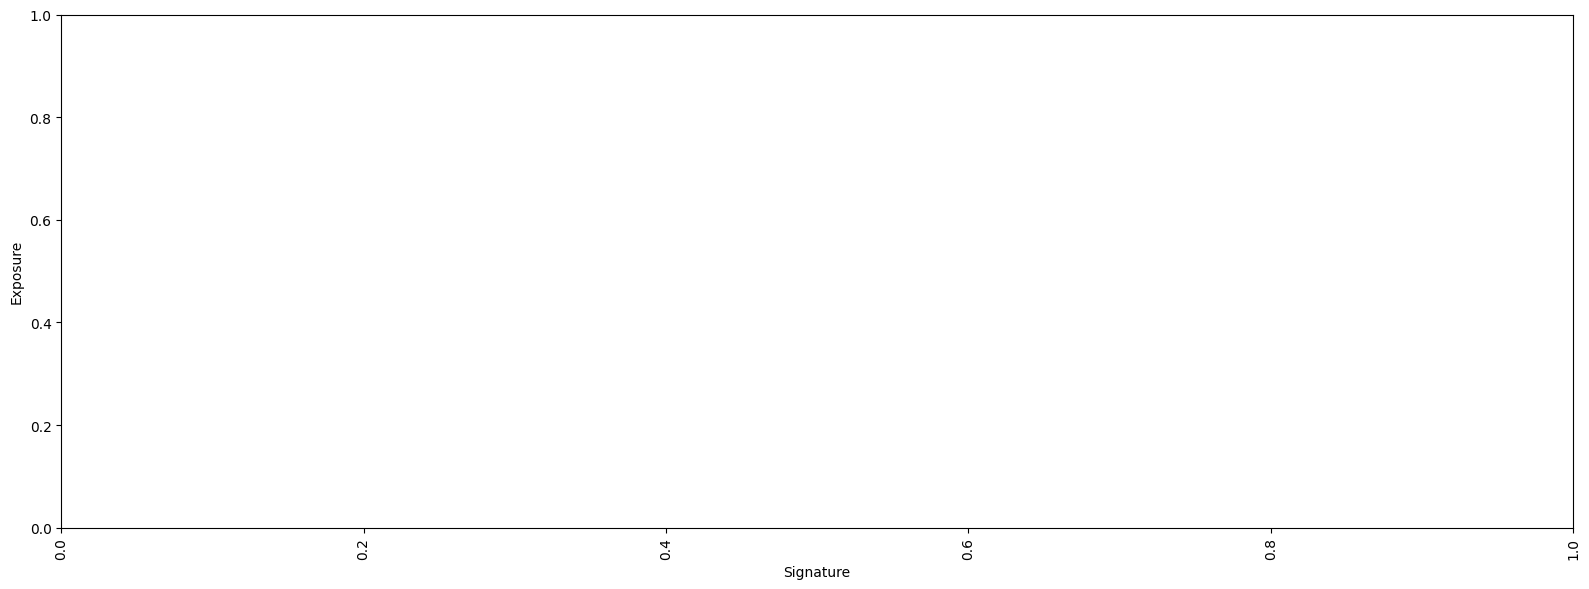

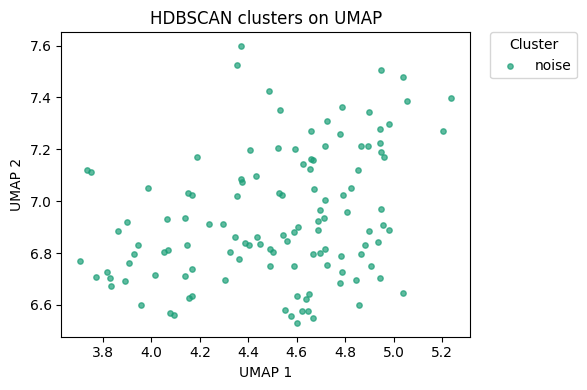

Error processing 125x2089: Need at least two groups in stats.kruskal()
Loaded 1402 cells.
Mutations per cell:
	min:  67
	mean: 352
	max:  918
Silhouette: 0.1587
DBCV: 0.1315


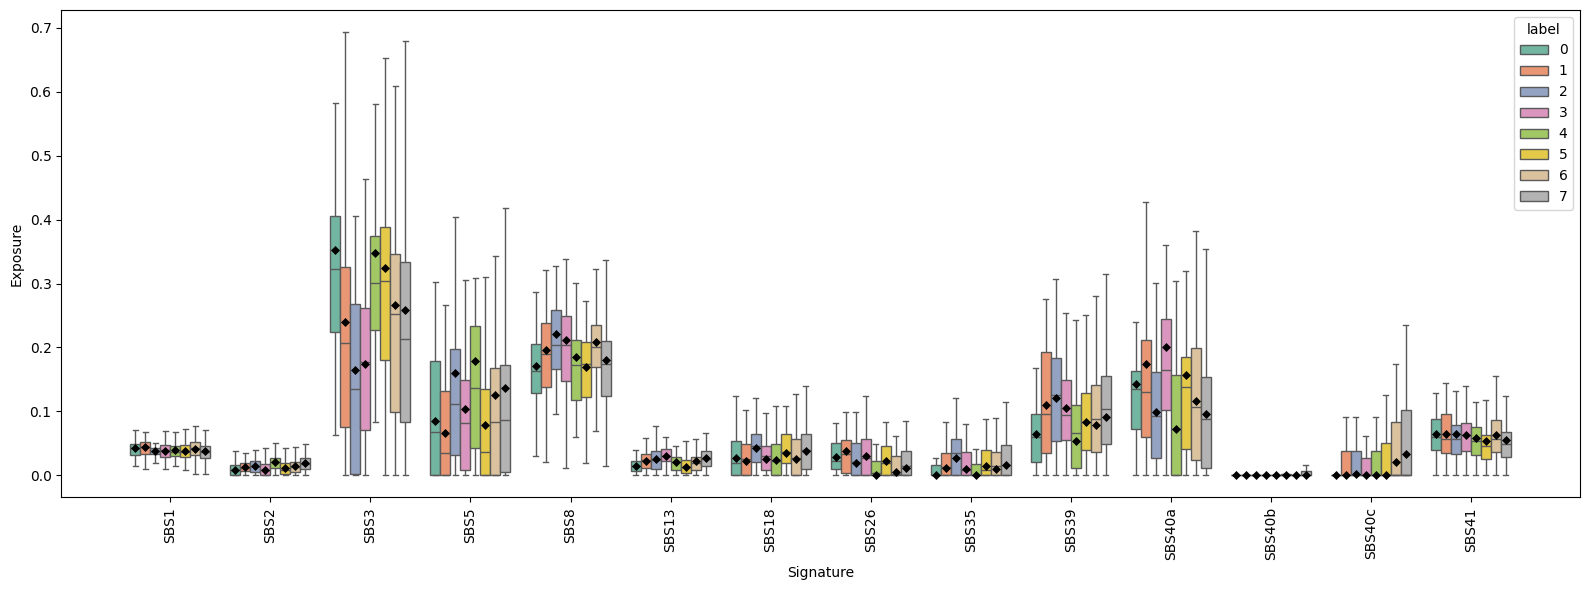

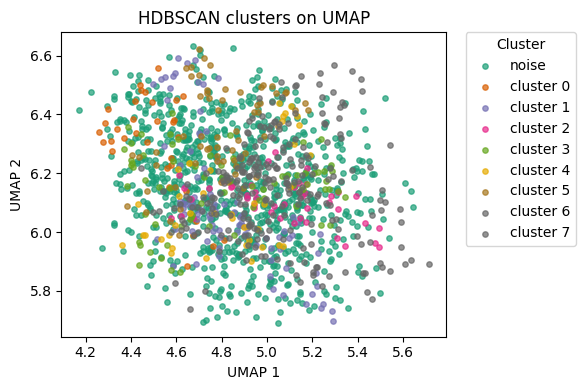

Loaded 146 cells.
Mutations per cell:
	min:  417
	mean: 770
	max:  1231
Could not compute scores (too few clusters).


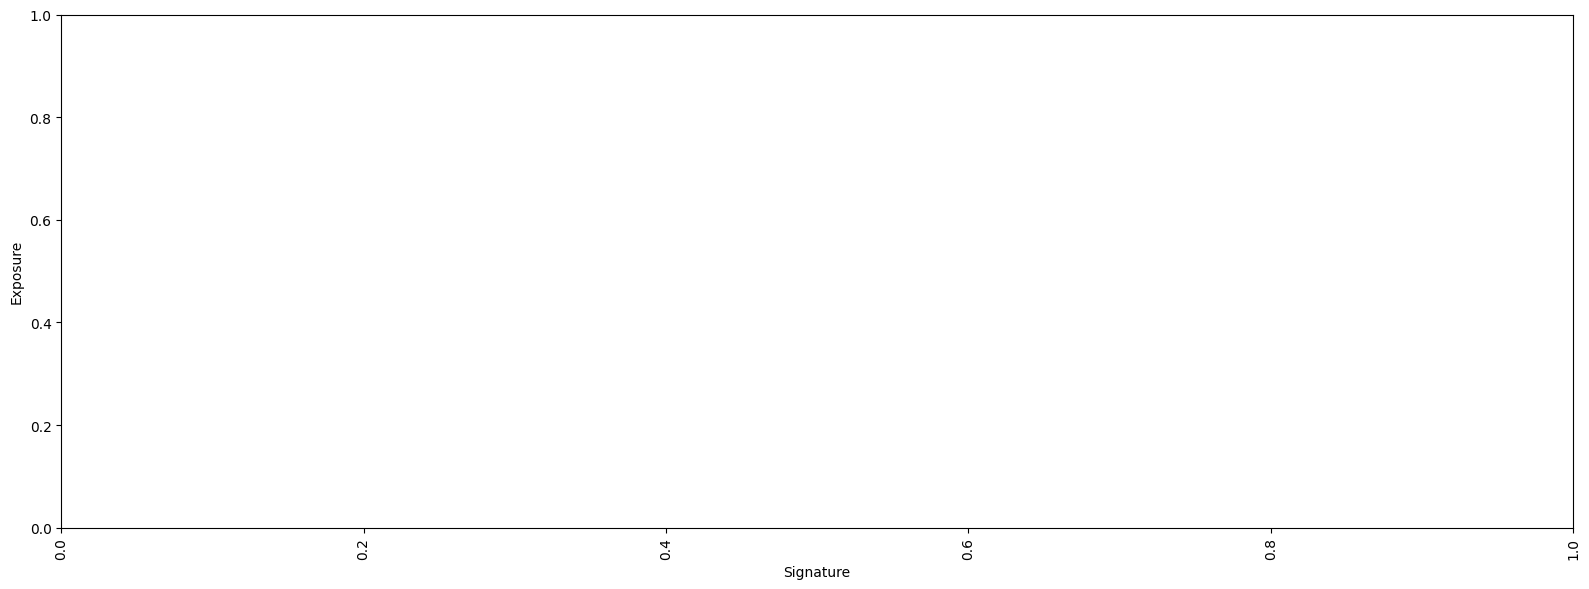

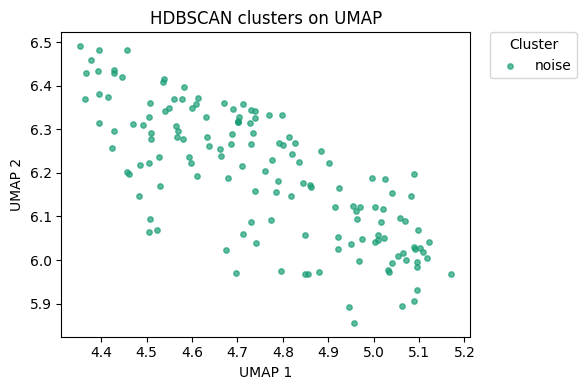

Error processing 146x15418: Need at least two groups in stats.kruskal()
Loaded 1360 cells.
Mutations per cell:
	min:  50
	mean: 119
	max:  294
Silhouette: 0.1508
DBCV: 0.0821


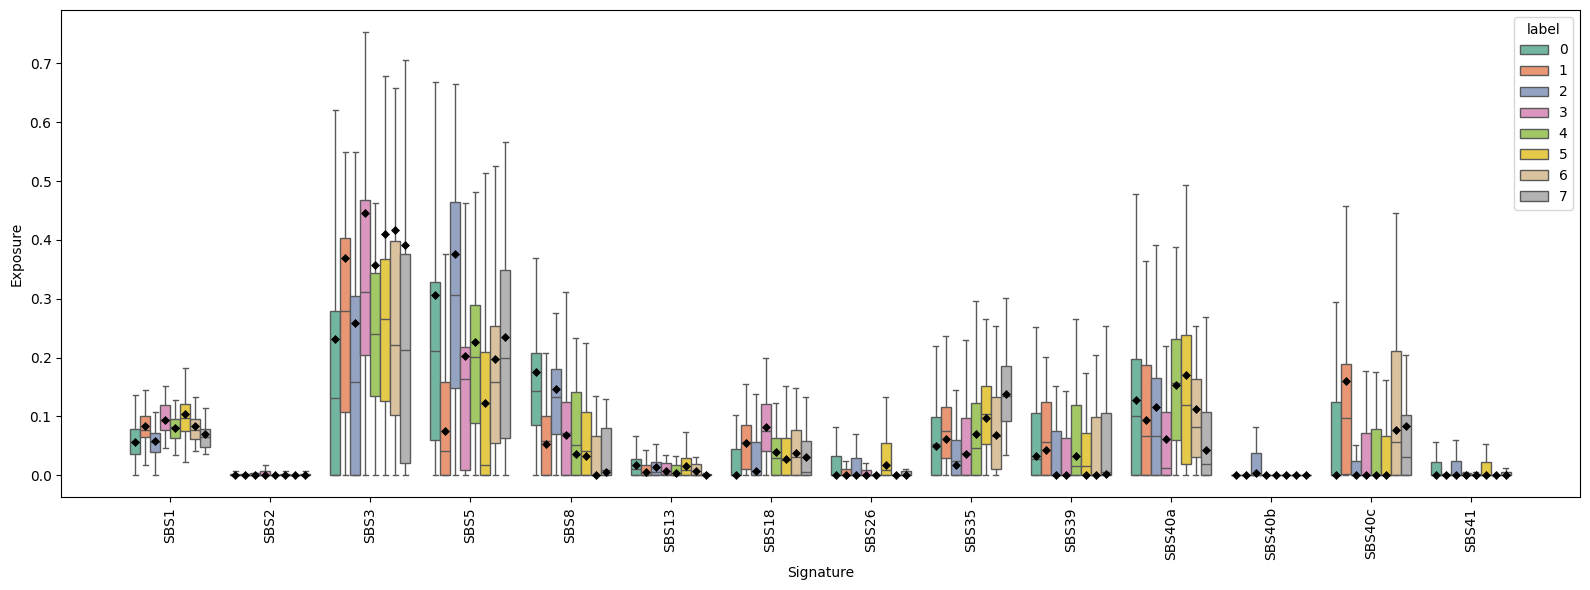

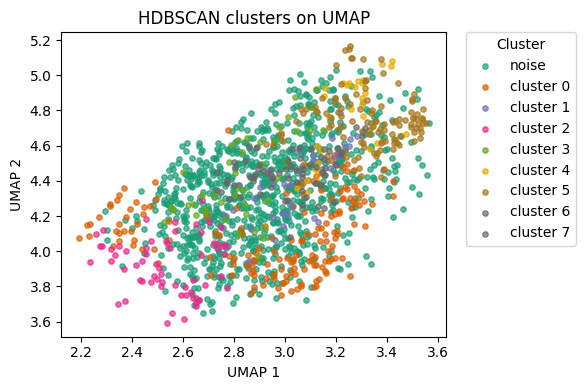

Loaded 1648 cells.
Mutations per cell:
	min:  55
	mean: 425
	max:  1058
Silhouette: 0.2557
DBCV: 0.1332


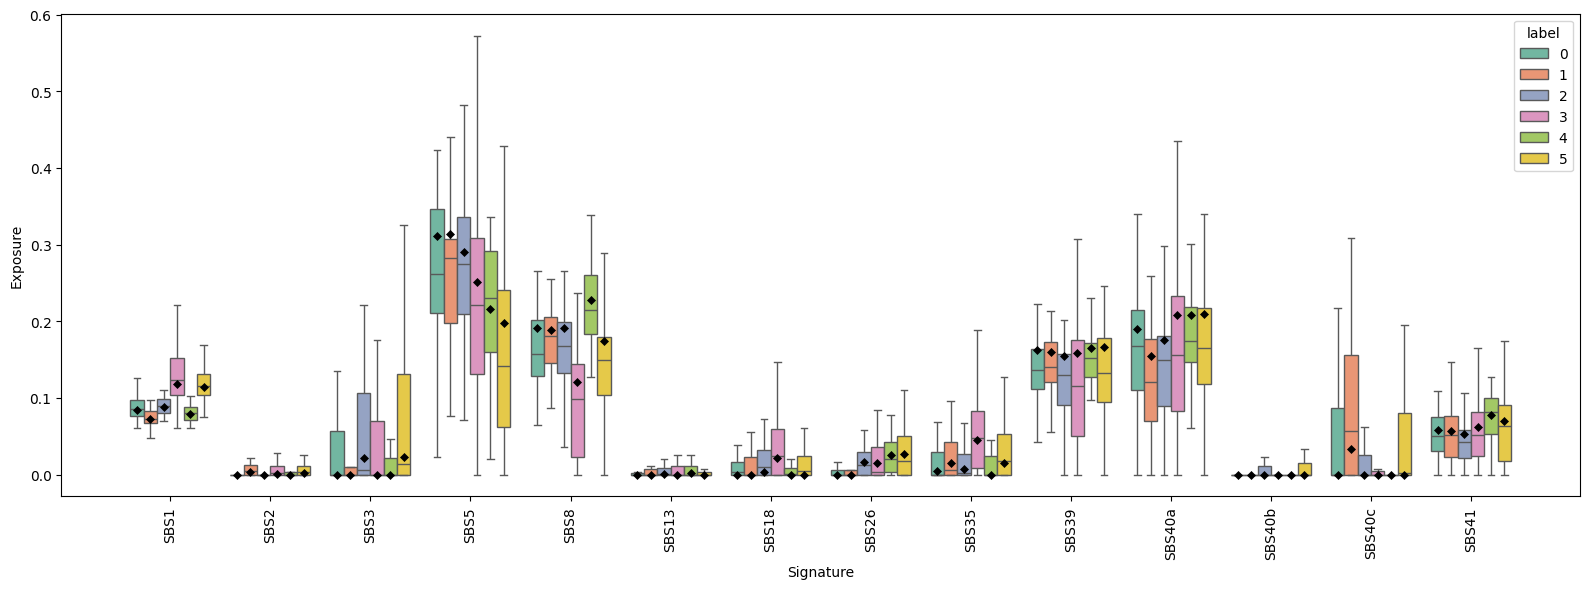

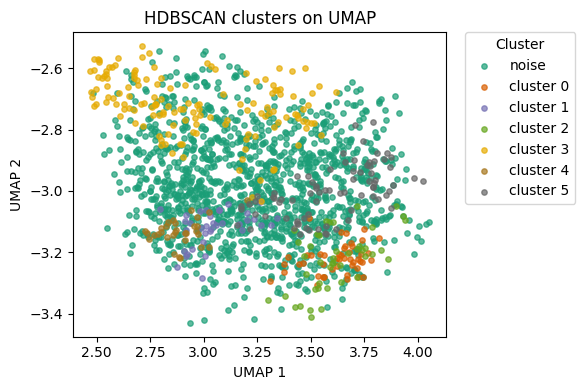

Loaded 164 cells.
Mutations per cell:
	min:  210
	mean: 489
	max:  1363
Silhouette: 0.4188
DBCV: 0.1816


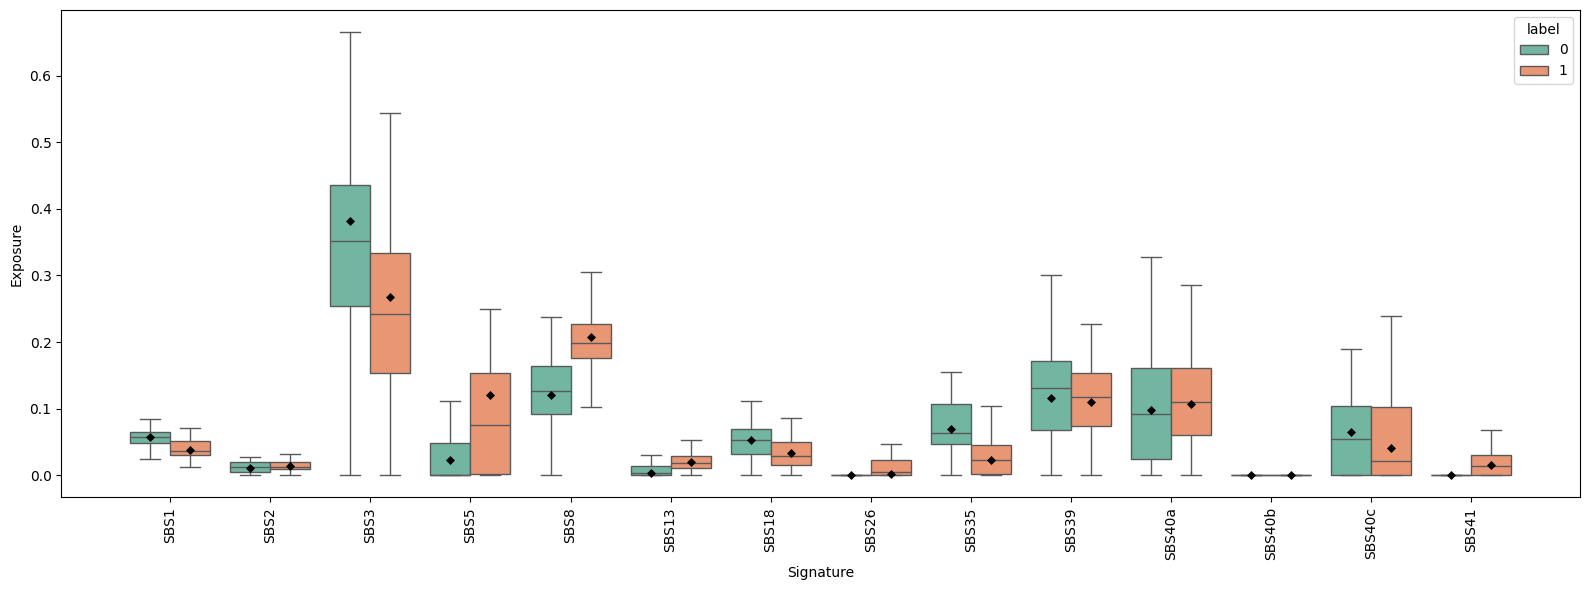

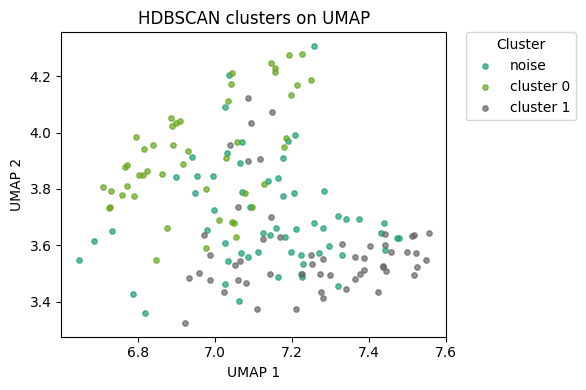

Loaded 1784 cells.
Mutations per cell:
	min:  57
	mean: 464
	max:  1317
Silhouette: 0.1873
DBCV: 0.1154


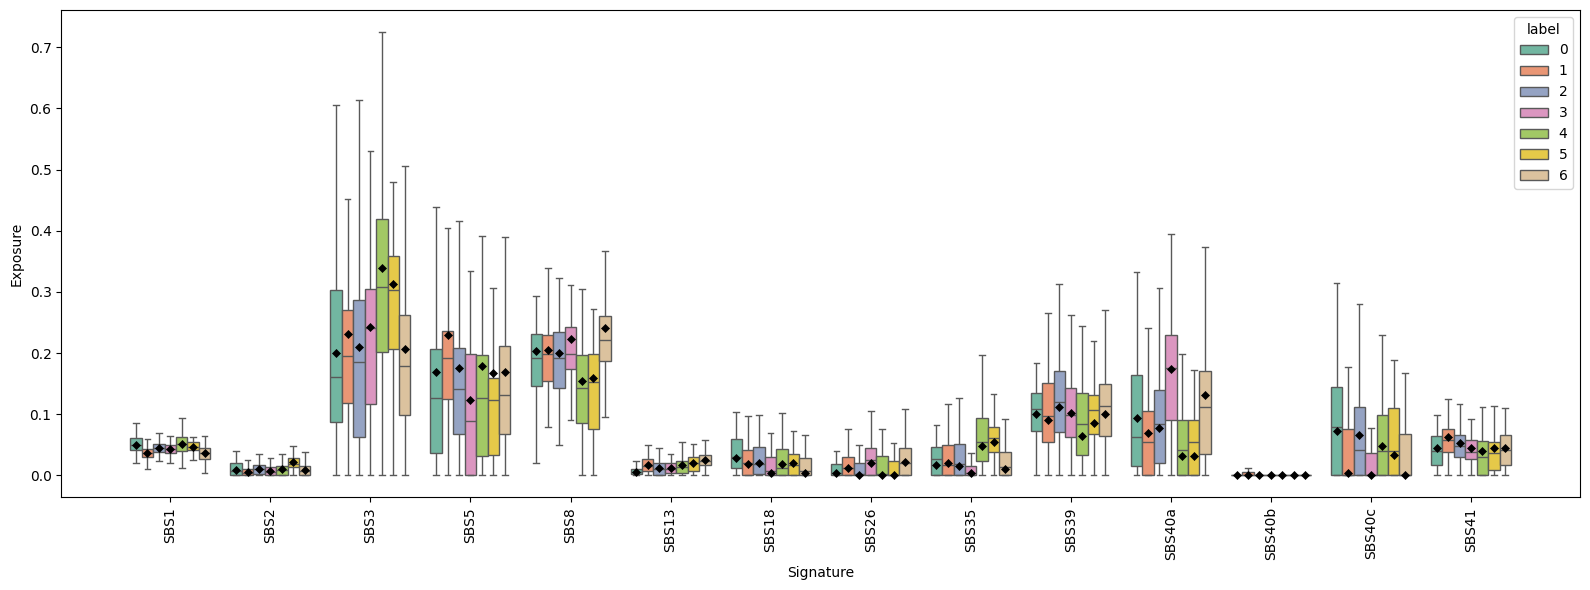

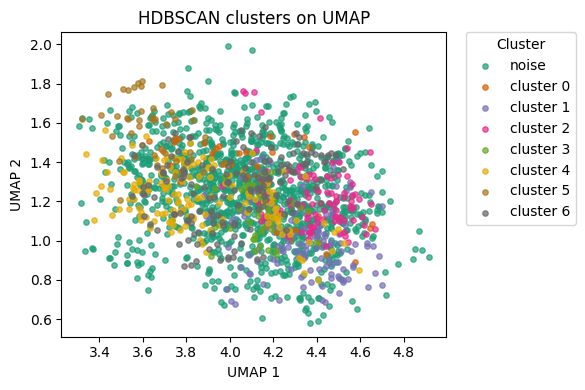

Loaded 1746 cells.
Mutations per cell:
	min:  50
	mean: 164
	max:  745
Silhouette: 0.2892
DBCV: 0.1175


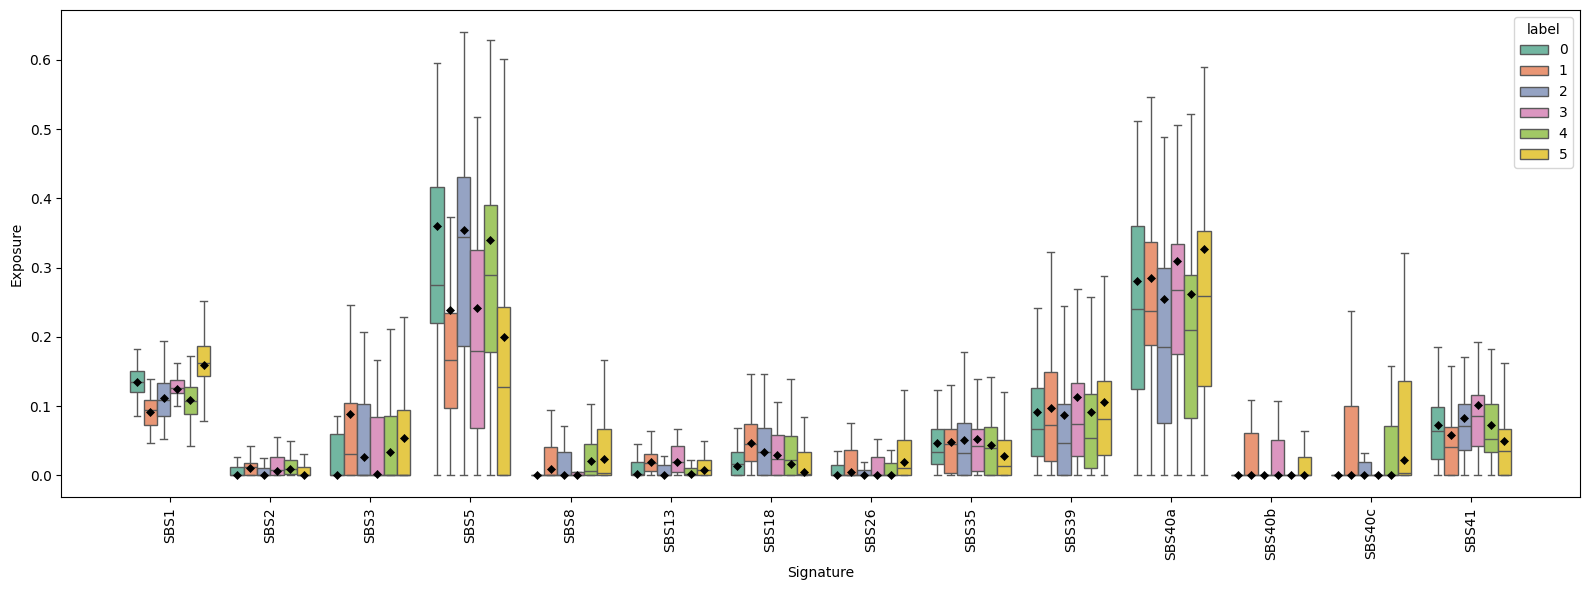

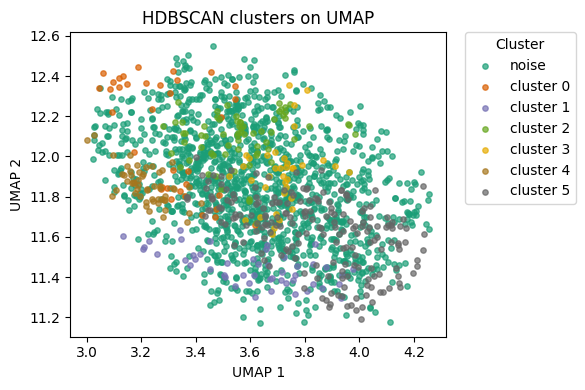

Loaded 1853 cells.
Mutations per cell:
	min:  50
	mean: 245
	max:  834
Silhouette: 0.3509
DBCV: 0.0360


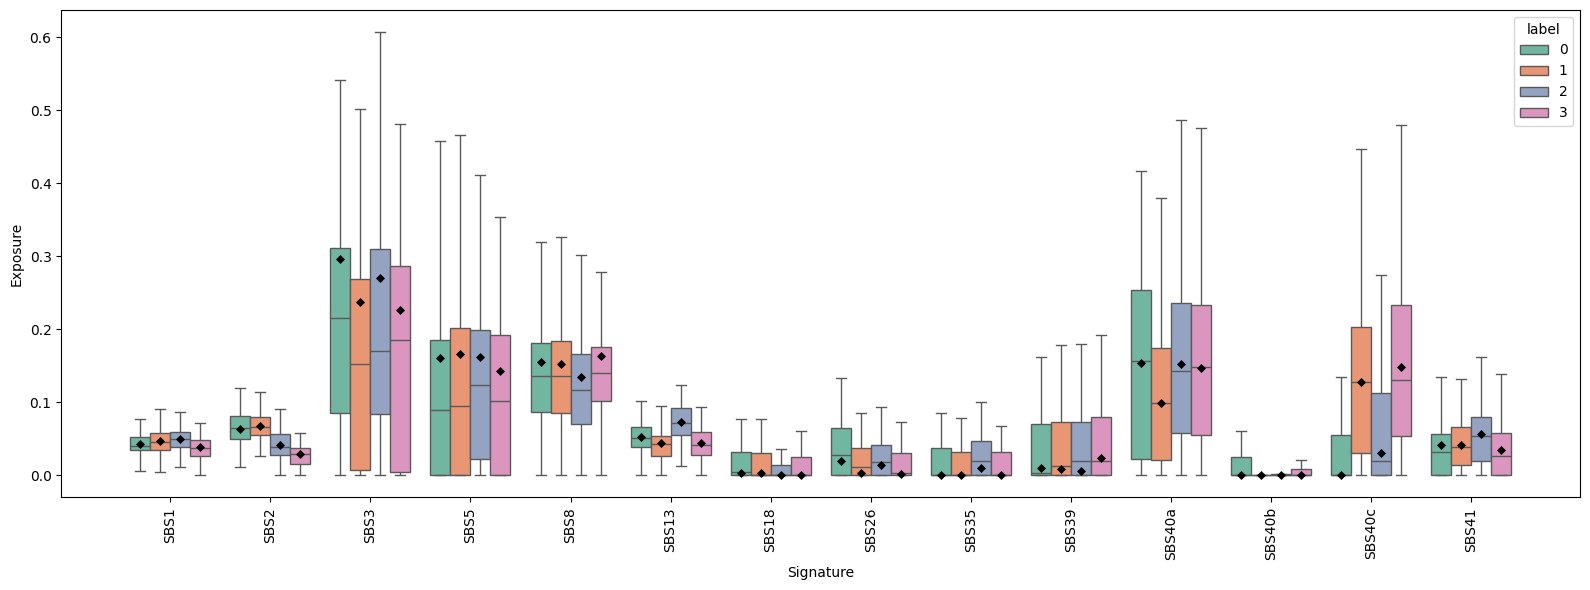

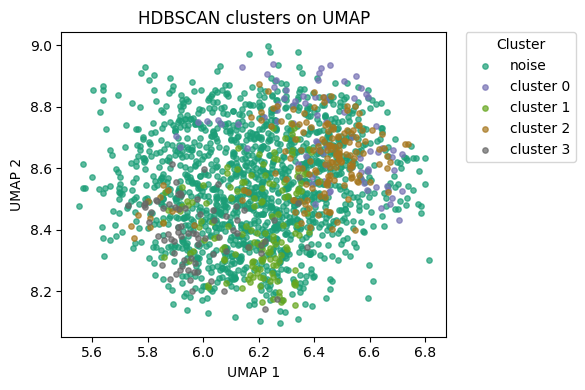

Loaded 2092 cells.
Mutations per cell:
	min:  50
	mean: 272
	max:  810
Silhouette: 0.1356
DBCV: 0.0726


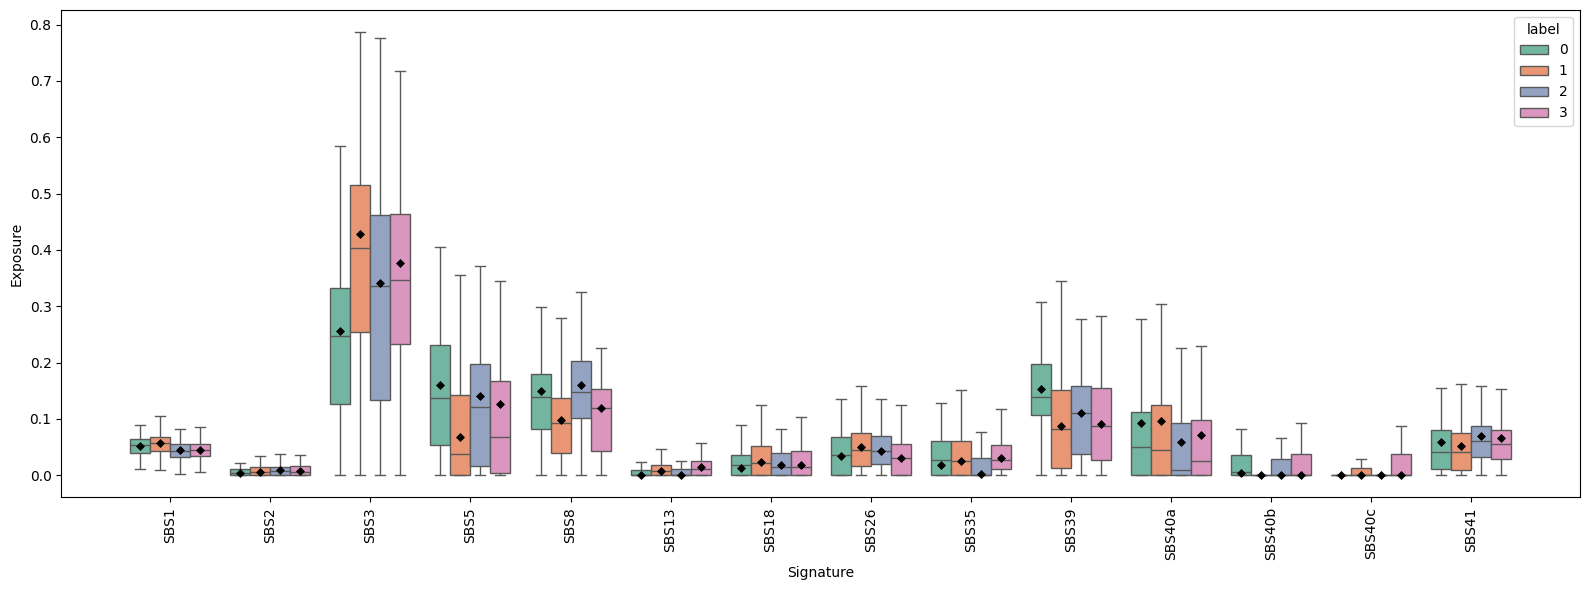

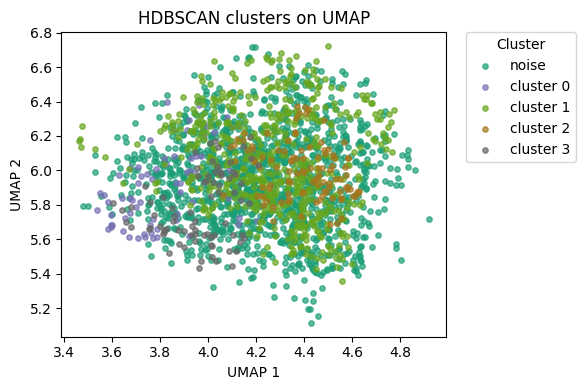

Loaded 234 cells.
Mutations per cell:
	min:  51
	mean: 280
	max:  538
Could not compute scores (too few clusters).


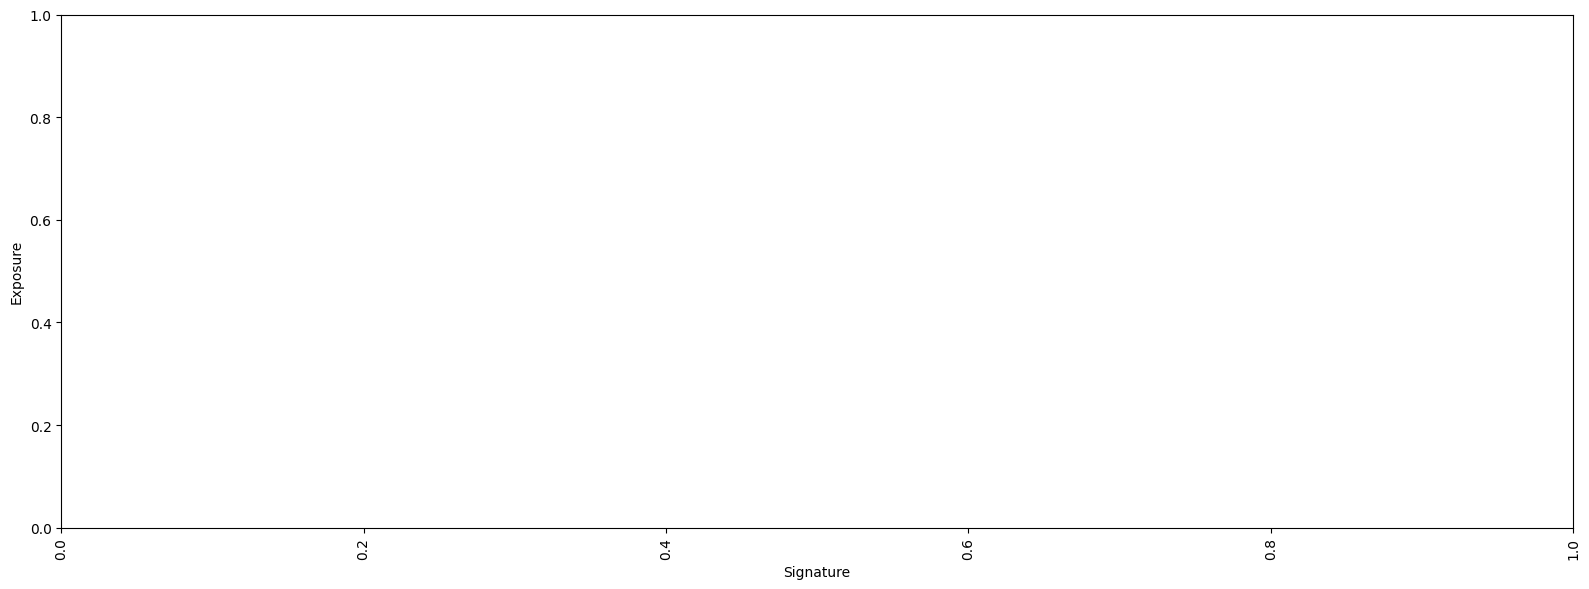

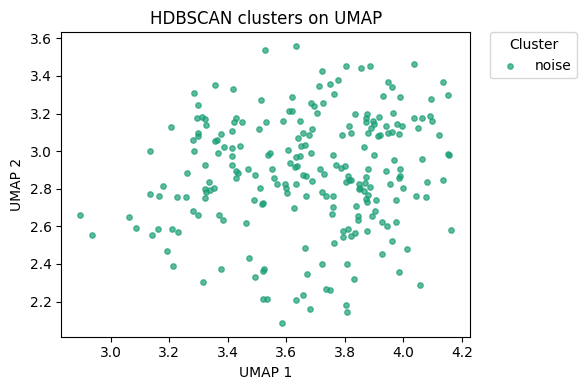

Error processing 242x9320: Need at least two groups in stats.kruskal()
Loaded 248 cells.
Mutations per cell:
	min:  60
	mean: 227
	max:  613
Silhouette: 0.2590
DBCV: 0.1065


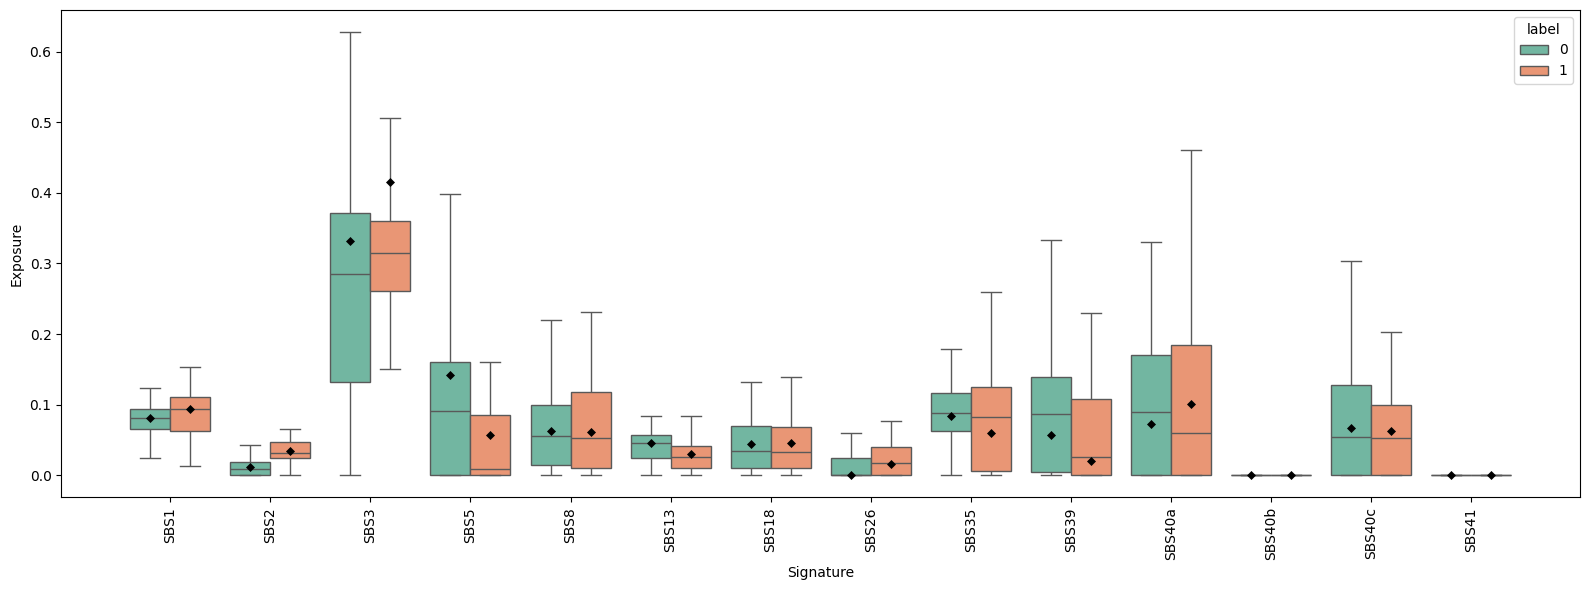

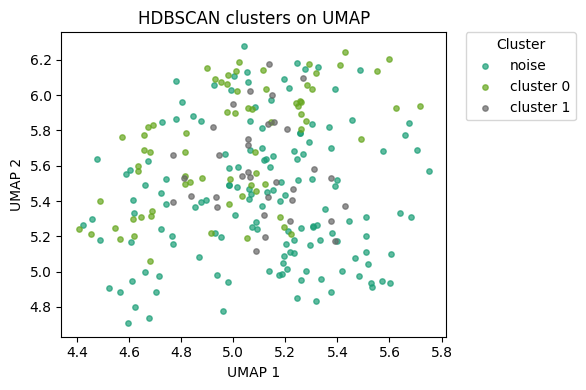

Loaded 314 cells.
Mutations per cell:
	min:  56
	mean: 287
	max:  732
Silhouette: 0.4575
DBCV: 0.1776


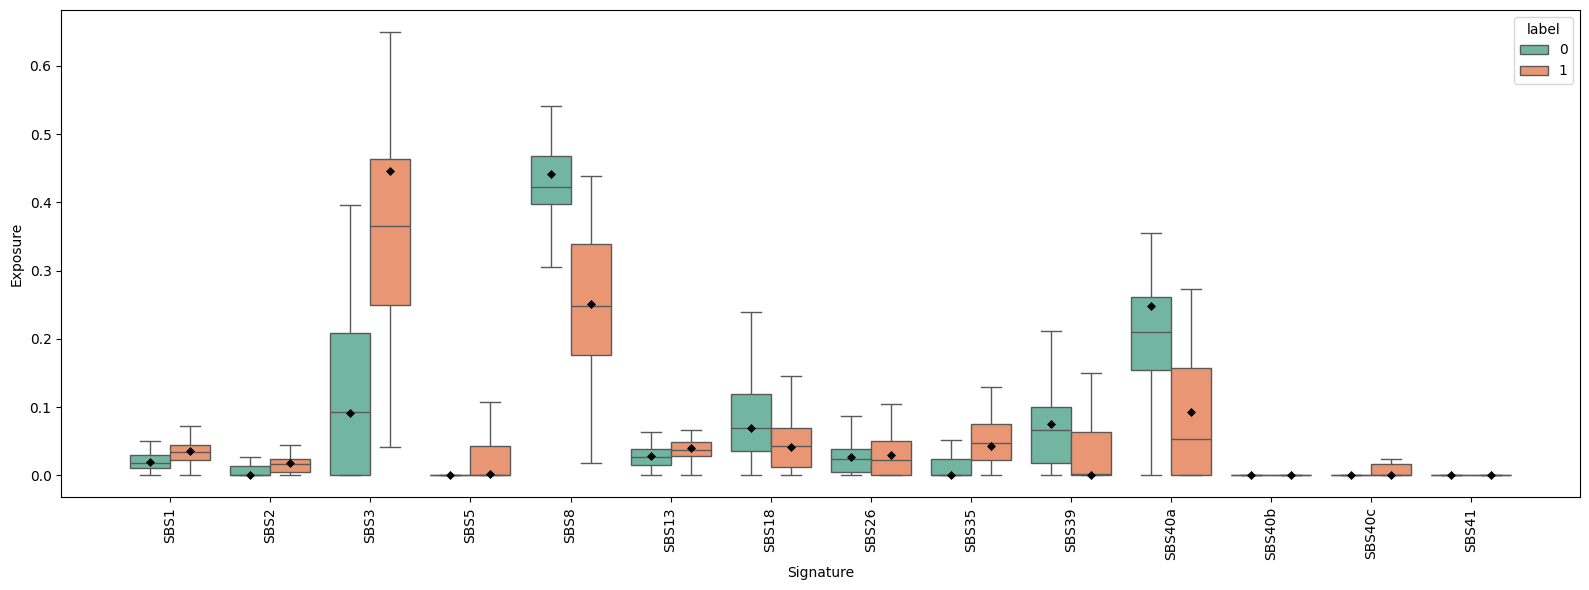

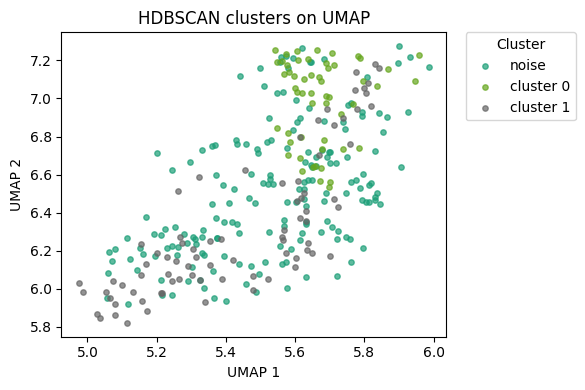

Loaded 325 cells.
Mutations per cell:
	min:  81
	mean: 379
	max:  878
Could not compute scores (too few clusters).


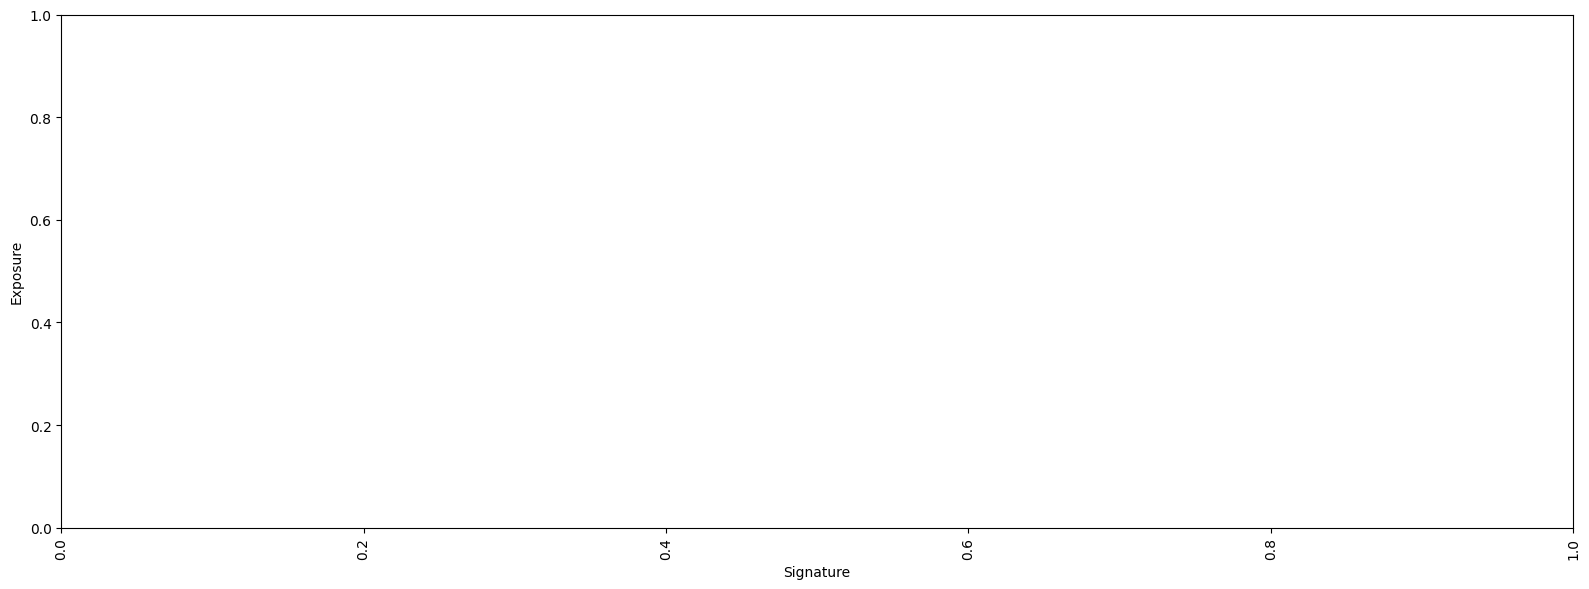

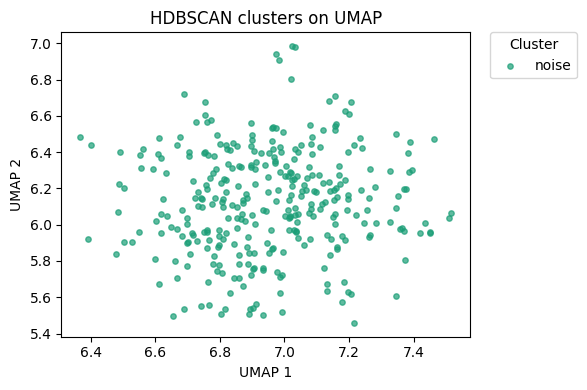

Error processing 325x7290: Need at least two groups in stats.kruskal()
Loaded 32 cells.
Mutations per cell:
	min:  151
	mean: 440
	max:  962
Could not compute scores (too few clusters).


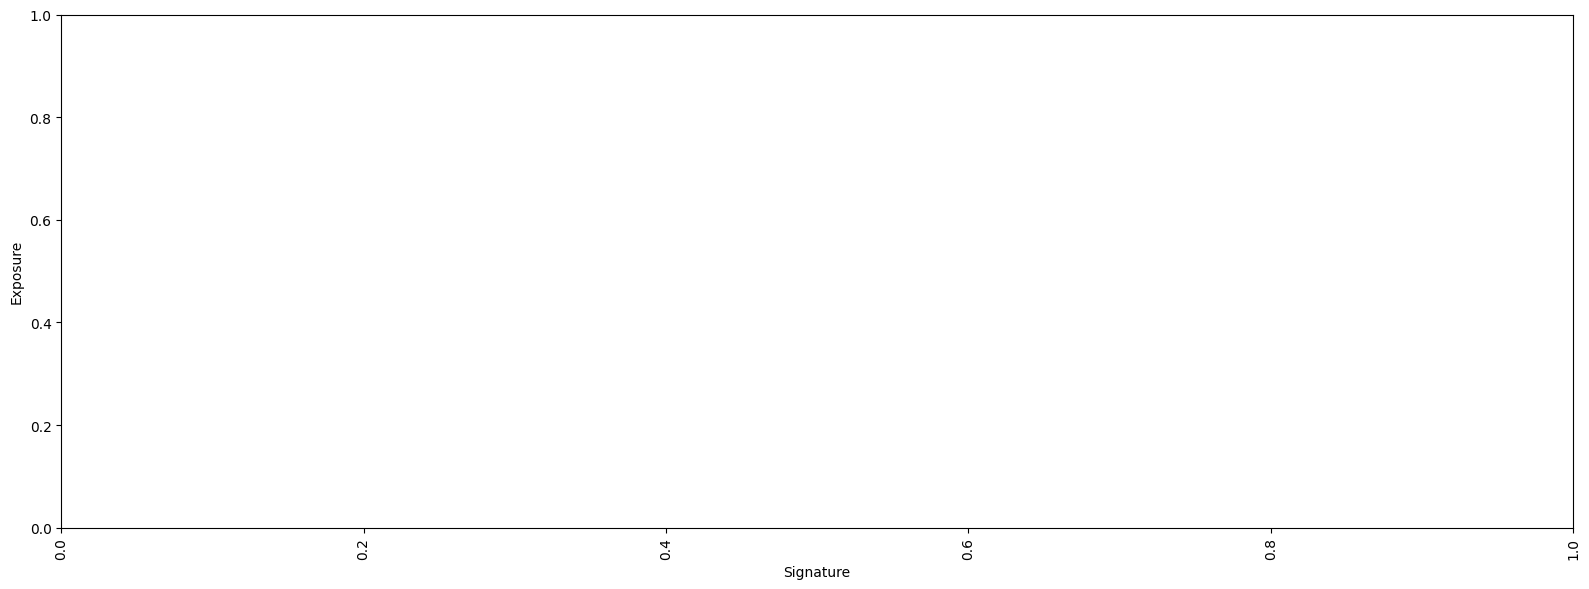

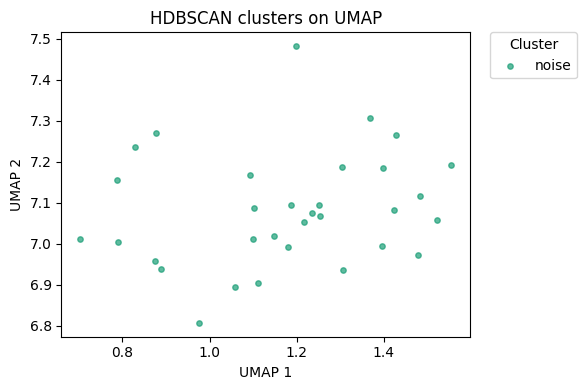

Error processing 32x5739: Need at least two groups in stats.kruskal()
Loaded 340 cells.
Mutations per cell:
	min:  157
	mean: 434
	max:  916
Could not compute scores (too few clusters).


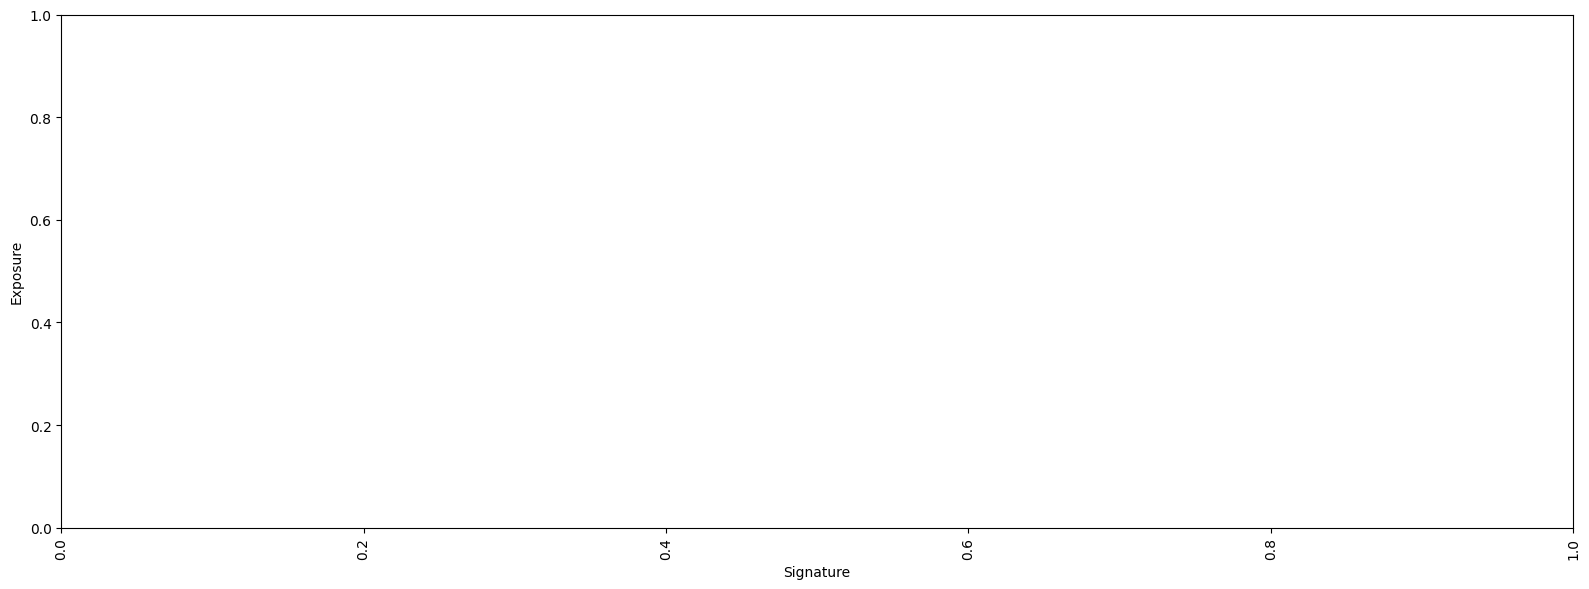

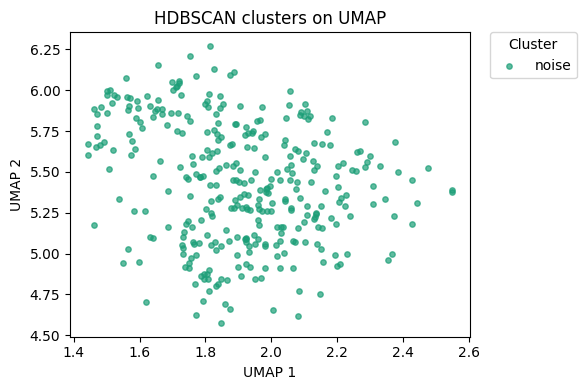

Error processing 340x14183: Need at least two groups in stats.kruskal()
Loaded 356 cells.
Mutations per cell:
	min:  159
	mean: 395
	max:  945
Silhouette: 0.2956
DBCV: 0.0363


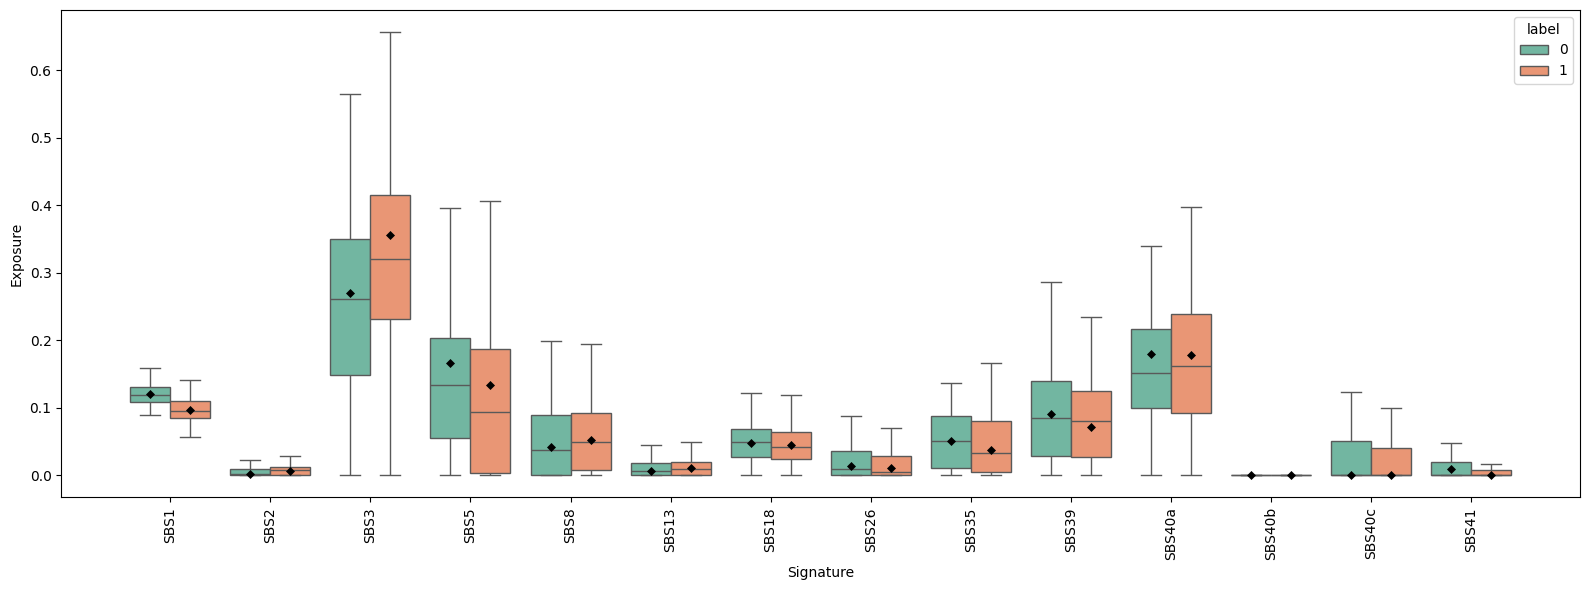

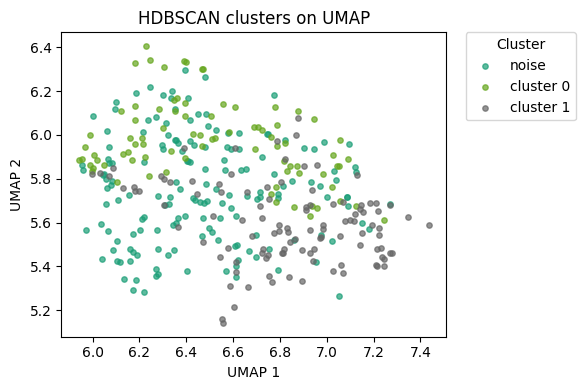

Loaded 375 cells.
Mutations per cell:
	min:  56
	mean: 399
	max:  809
Silhouette: 0.1605
DBCV: 0.0619


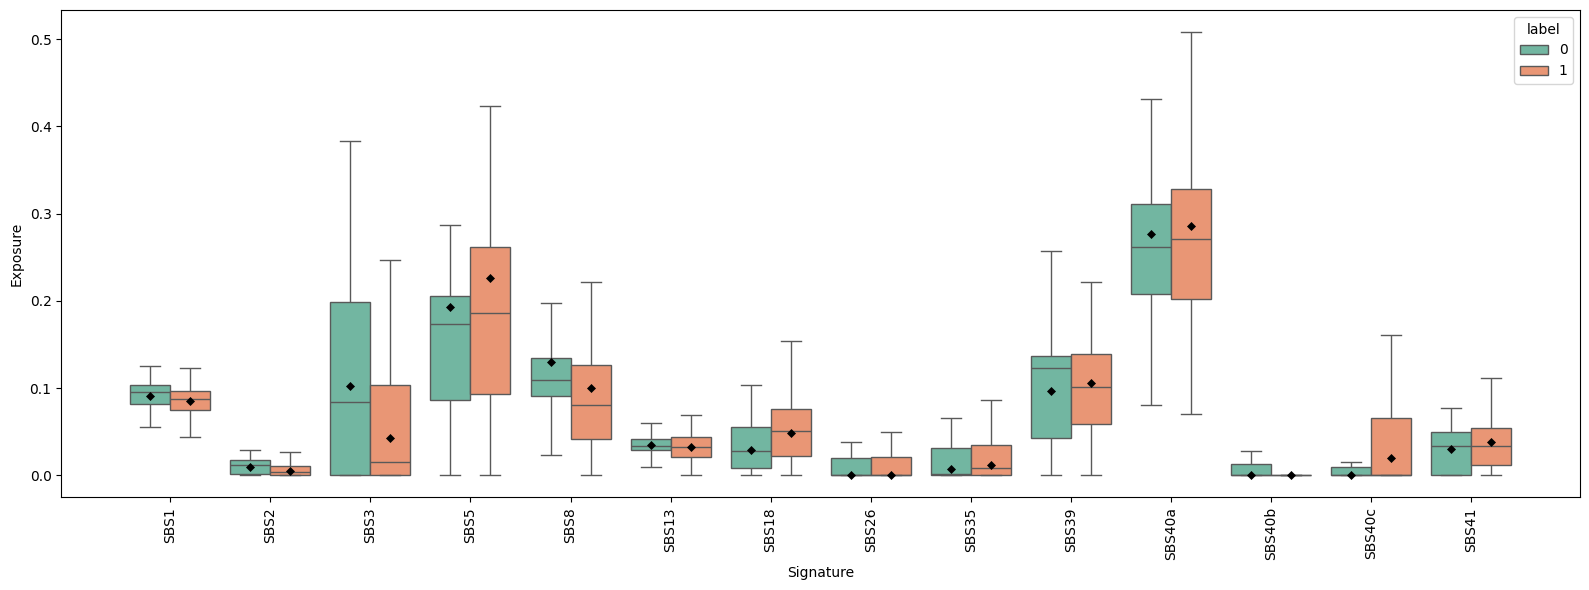

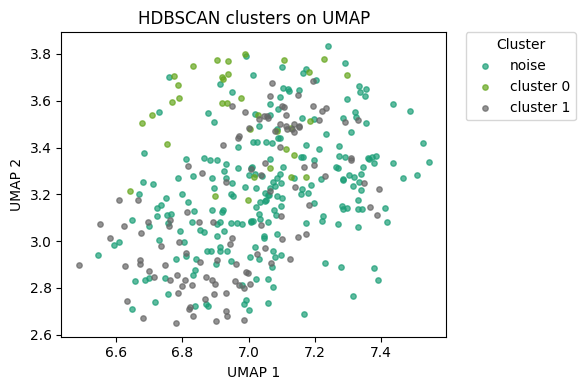

Loaded 363 cells.
Mutations per cell:
	min:  55
	mean: 286
	max:  579
Silhouette: 0.2408
DBCV: 0.2037


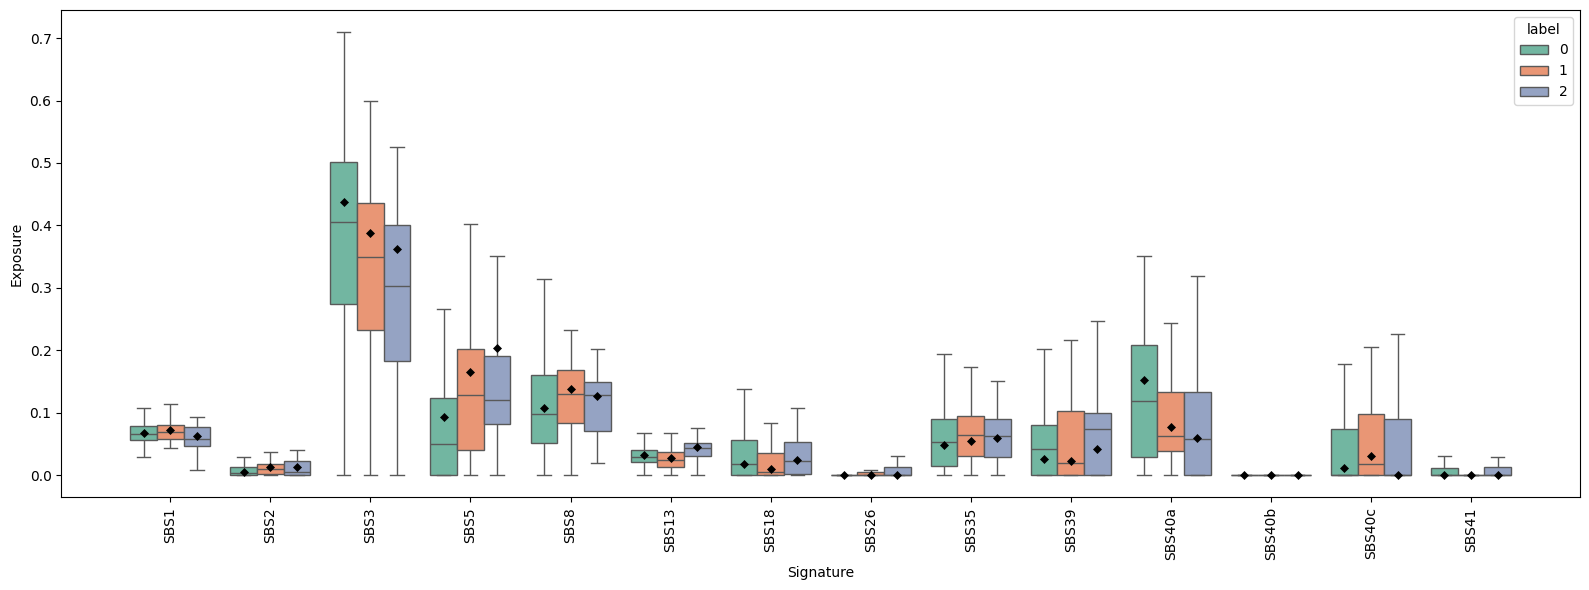

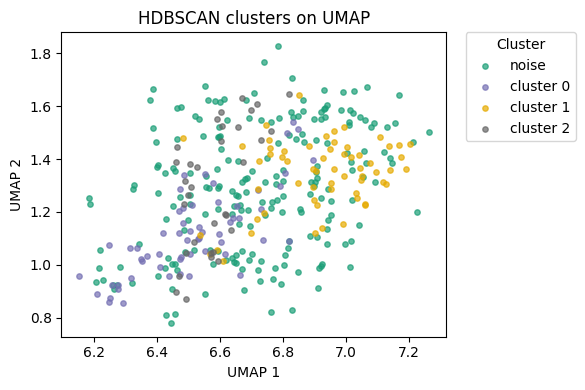

Loaded 369 cells.
Mutations per cell:
	min:  51
	mean: 135
	max:  260
Silhouette: 0.1318
DBCV: 0.0715


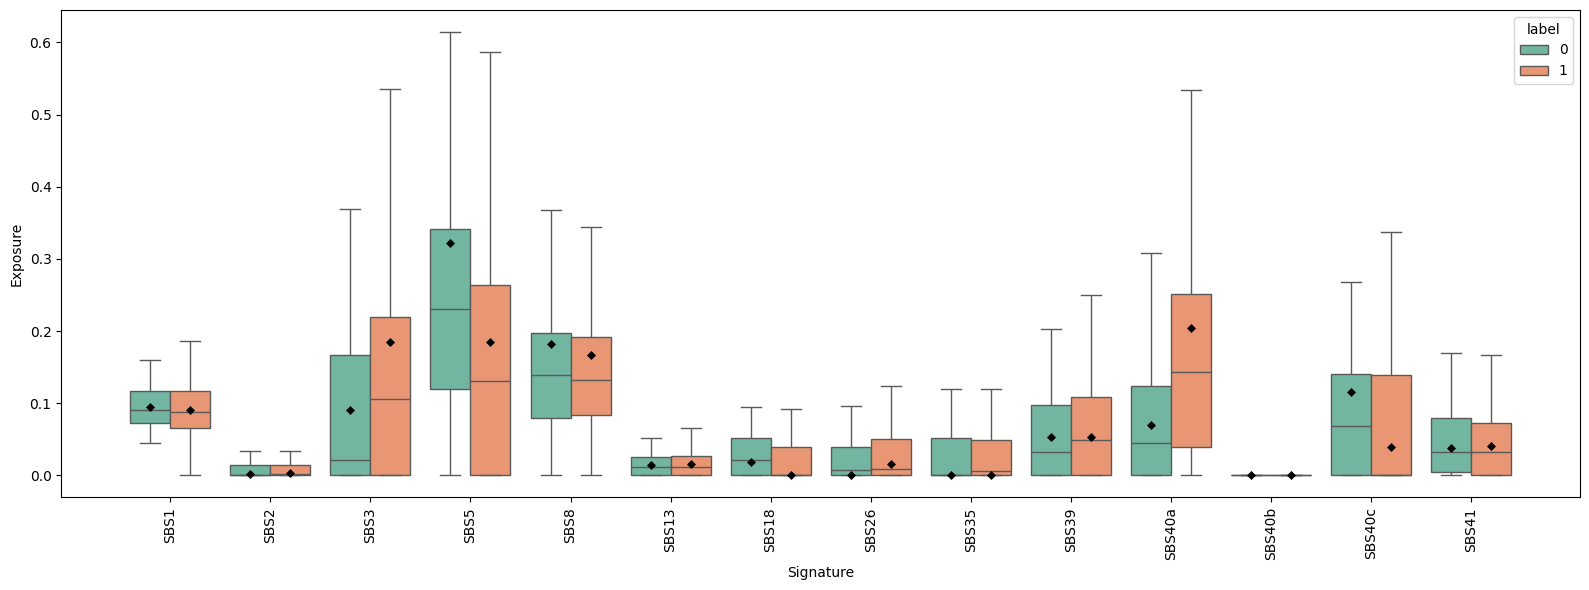

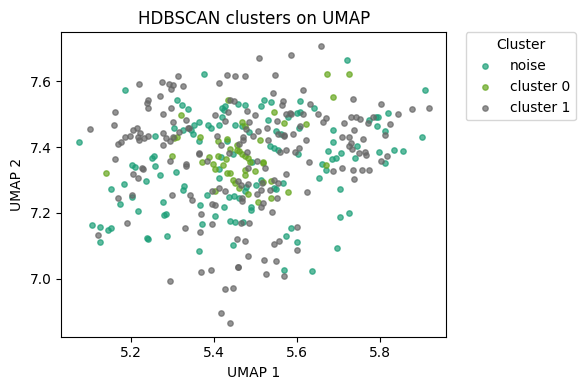

Loaded 432 cells.
Mutations per cell:
	min:  77
	mean: 331
	max:  844
Silhouette: 0.2709
DBCV: 0.1123


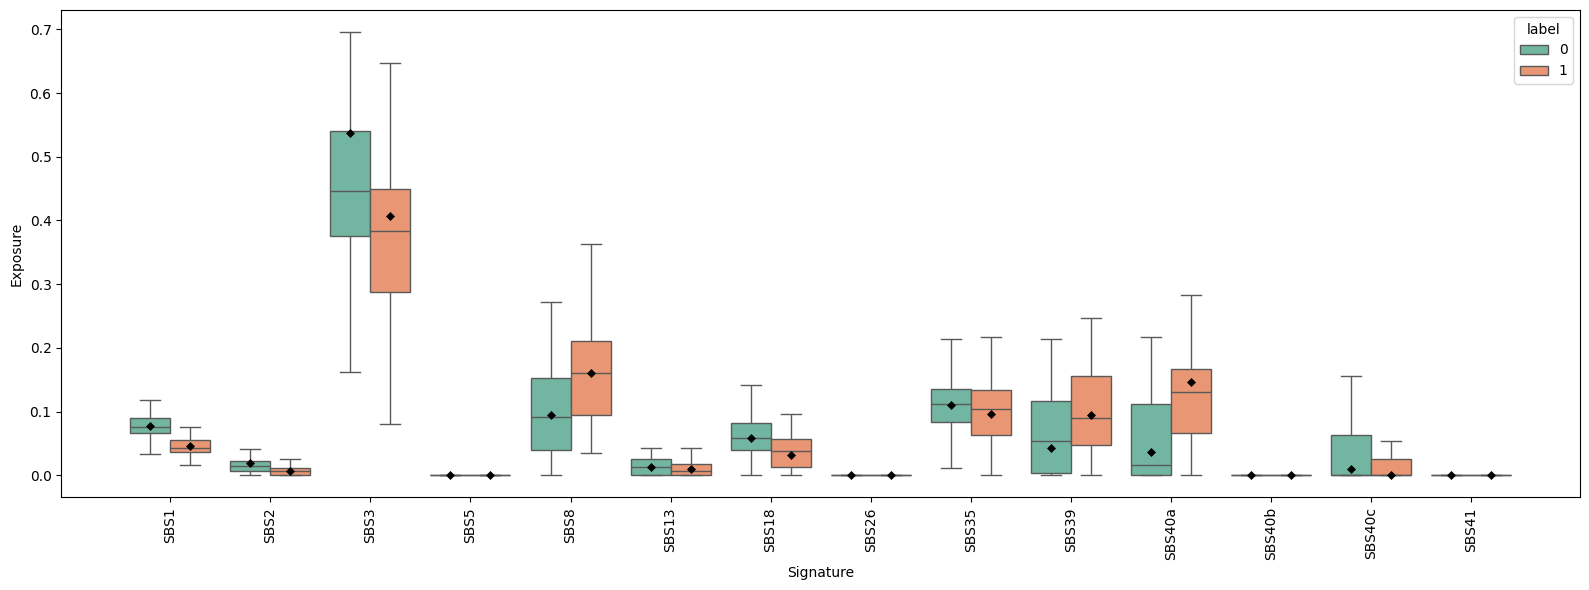

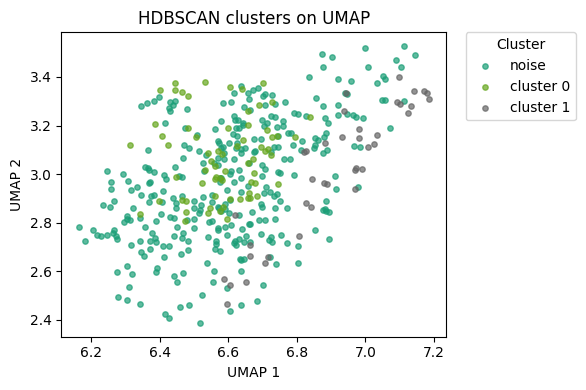

Loaded 460 cells.
Mutations per cell:
	min:  50
	mean: 250
	max:  578
Silhouette: 0.3758
DBCV: 0.3846


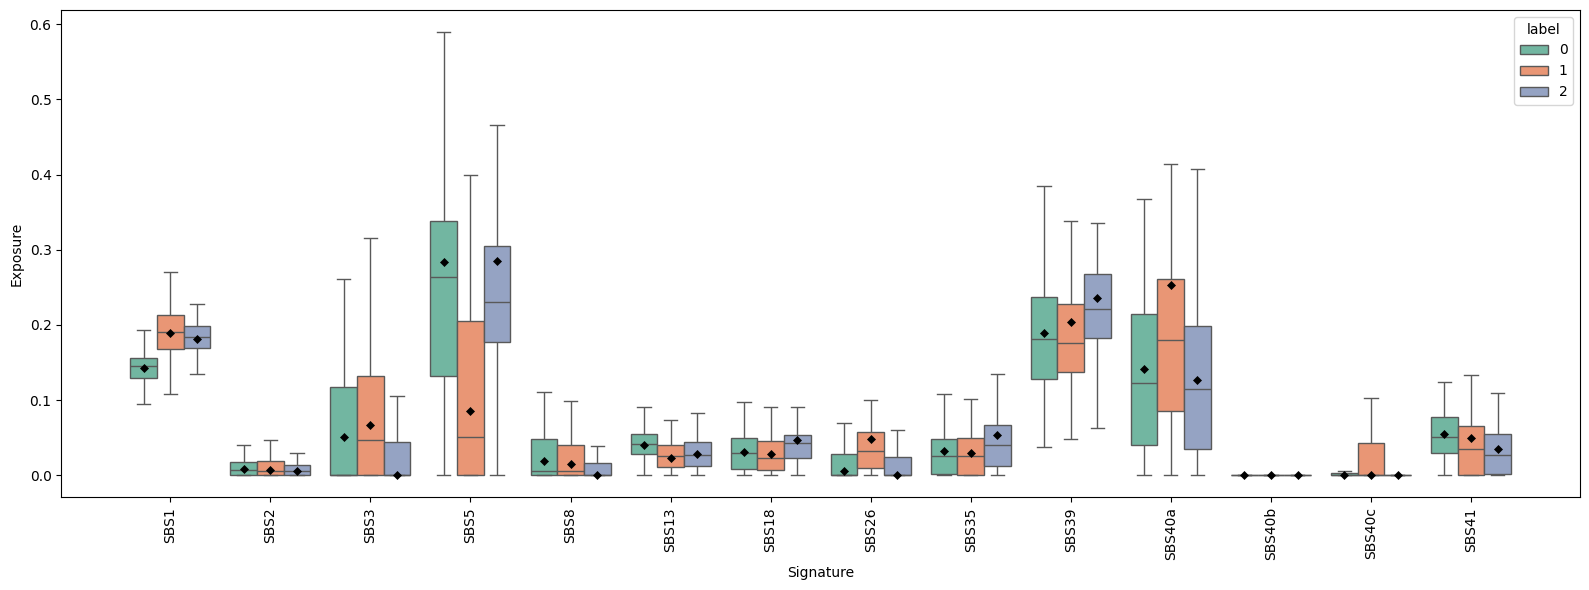

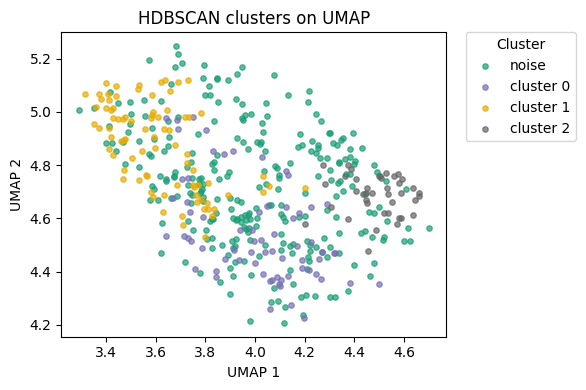

Loaded 518 cells.
Mutations per cell:
	min:  73
	mean: 520
	max:  1212
Silhouette: 0.1729
DBCV: -0.0251


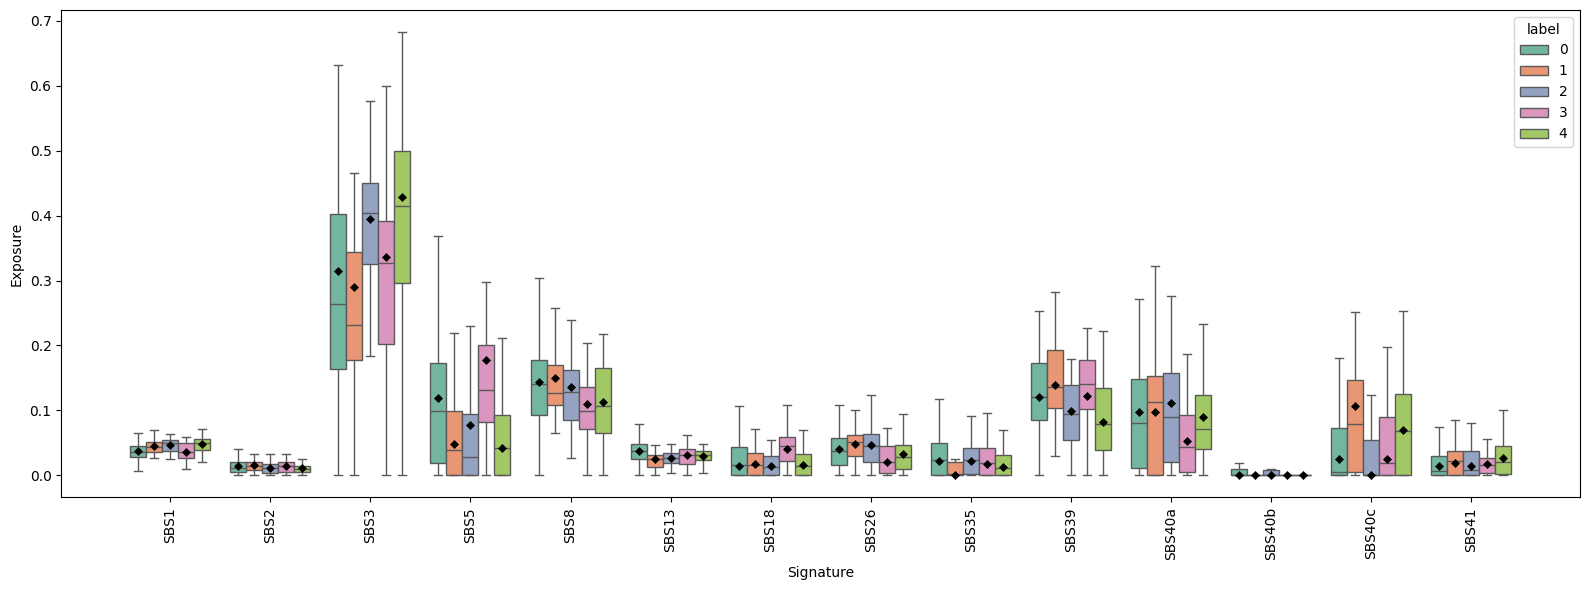

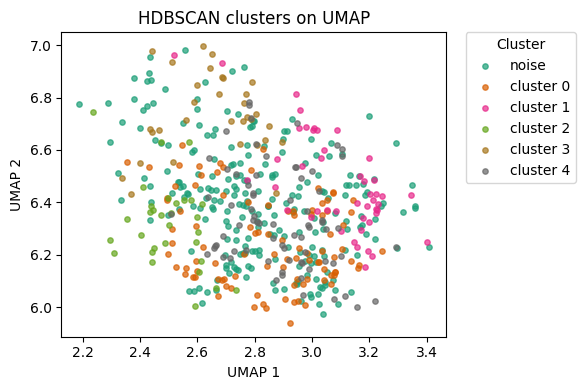

Loaded 559 cells.
Mutations per cell:
	min:  60
	mean: 370
	max:  732
Silhouette: 0.1537
DBCV: -0.0721


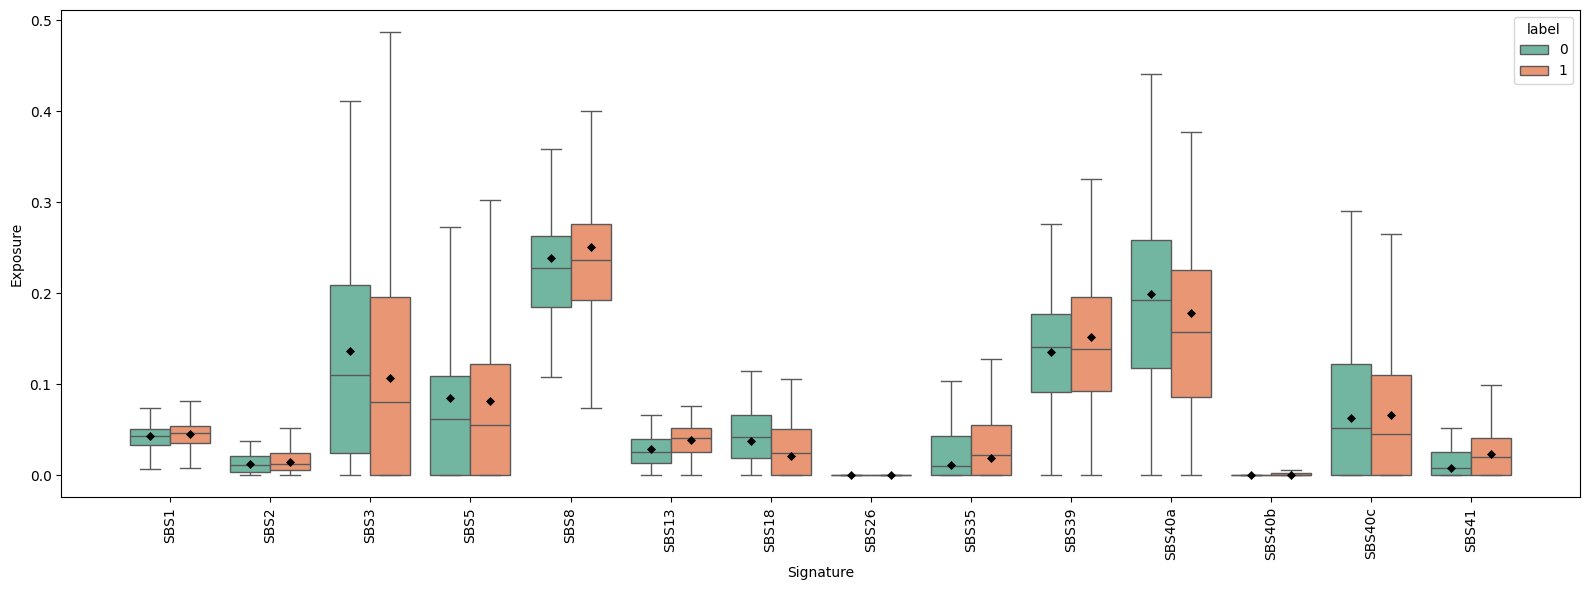

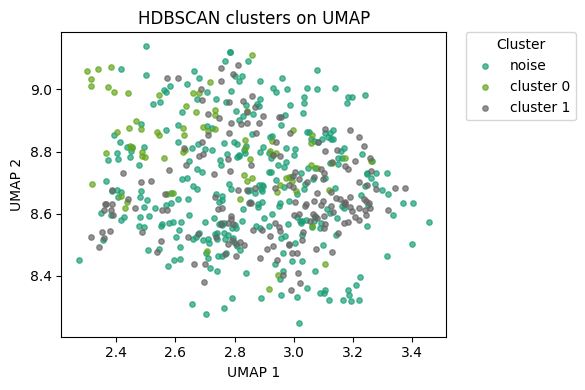

Loaded 563 cells.
Mutations per cell:
	min:  53
	mean: 228
	max:  684
Silhouette: 0.1875
DBCV: 0.1510


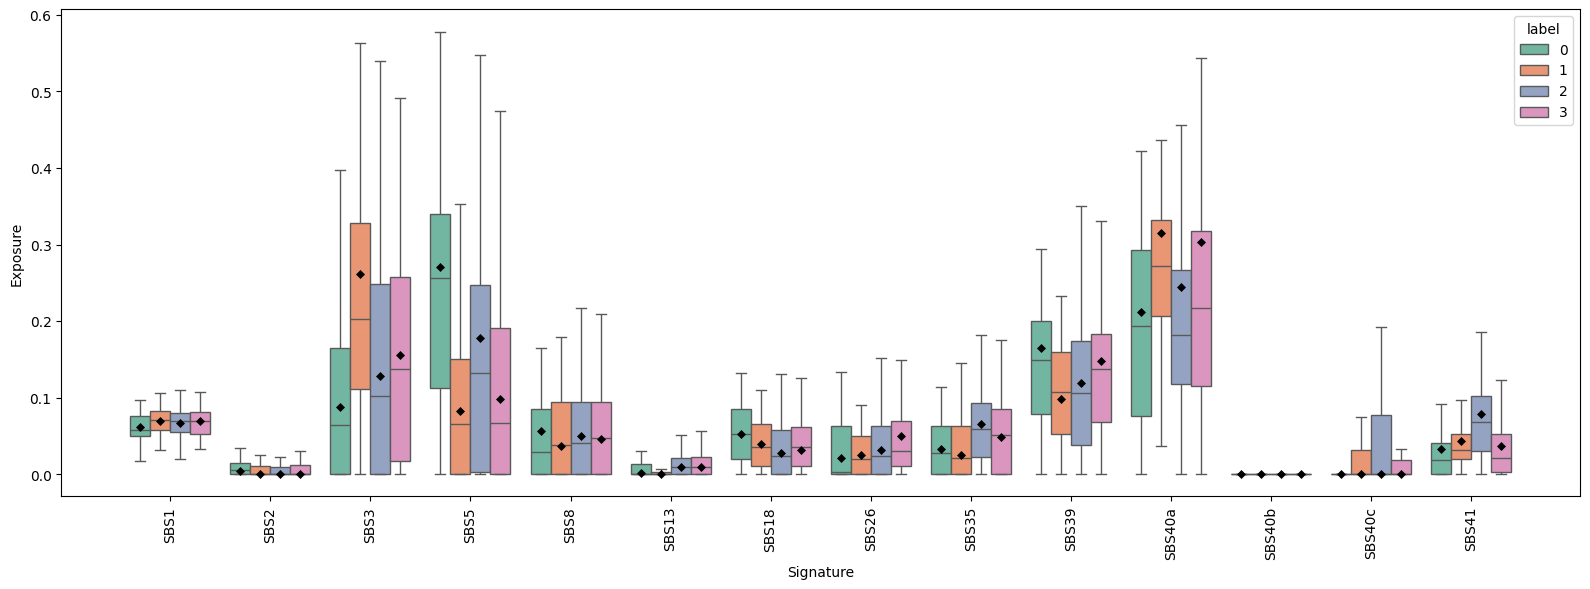

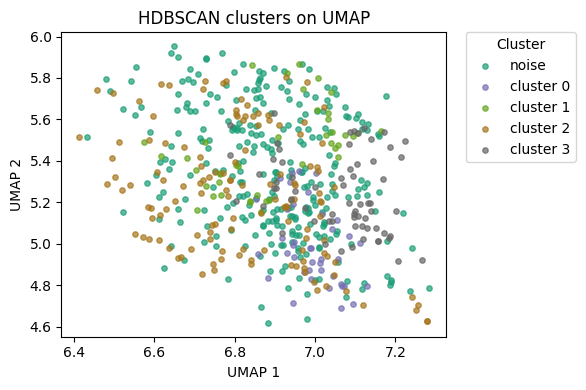

Loaded 56 cells.
Mutations per cell:
	min:  166
	mean: 401
	max:  667
Could not compute scores (too few clusters).


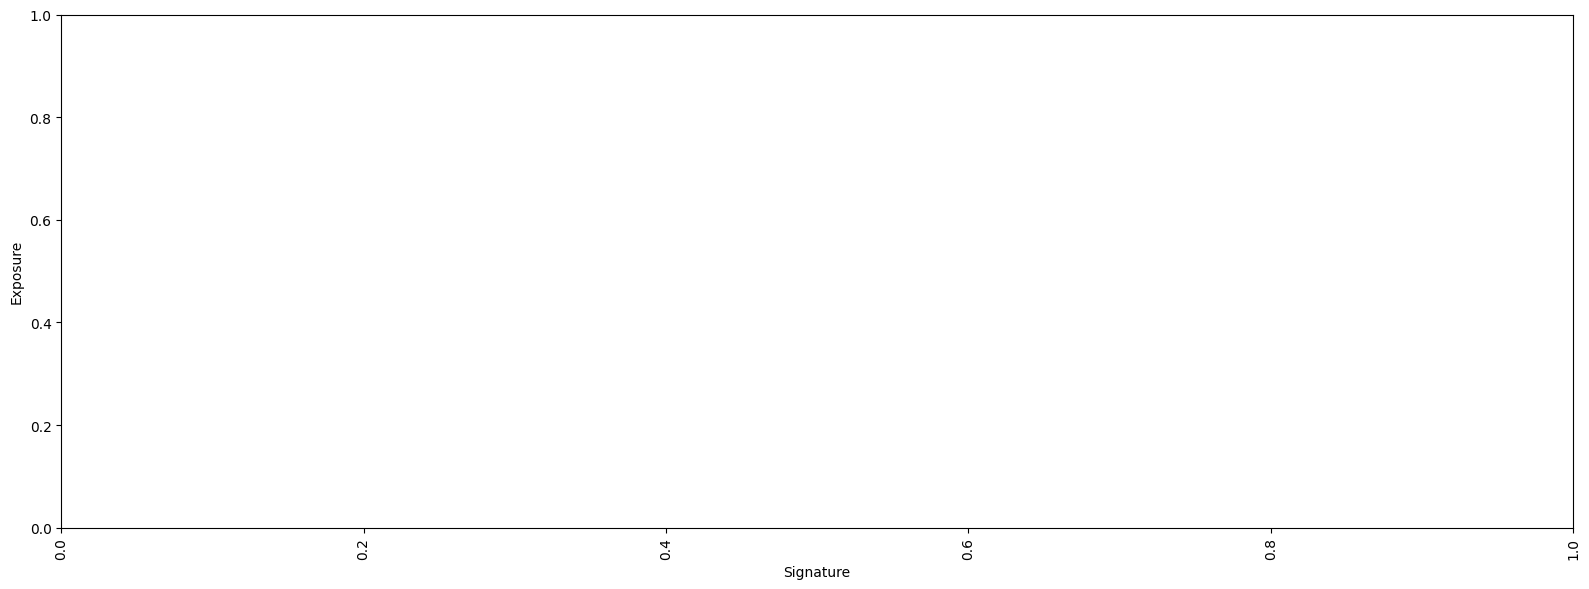

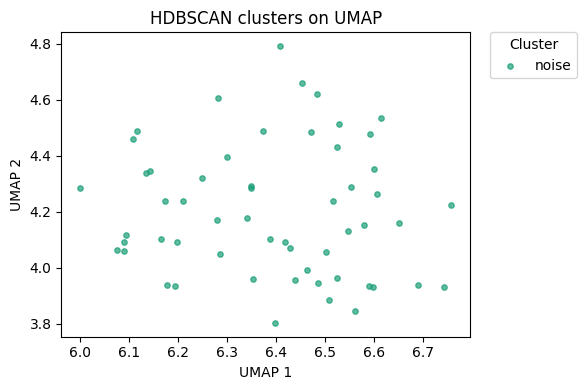

Error processing 56x13065: Need at least two groups in stats.kruskal()
Loaded 612 cells.
Mutations per cell:
	min:  67
	mean: 340
	max:  841
Silhouette: 0.1798
DBCV: 0.0810


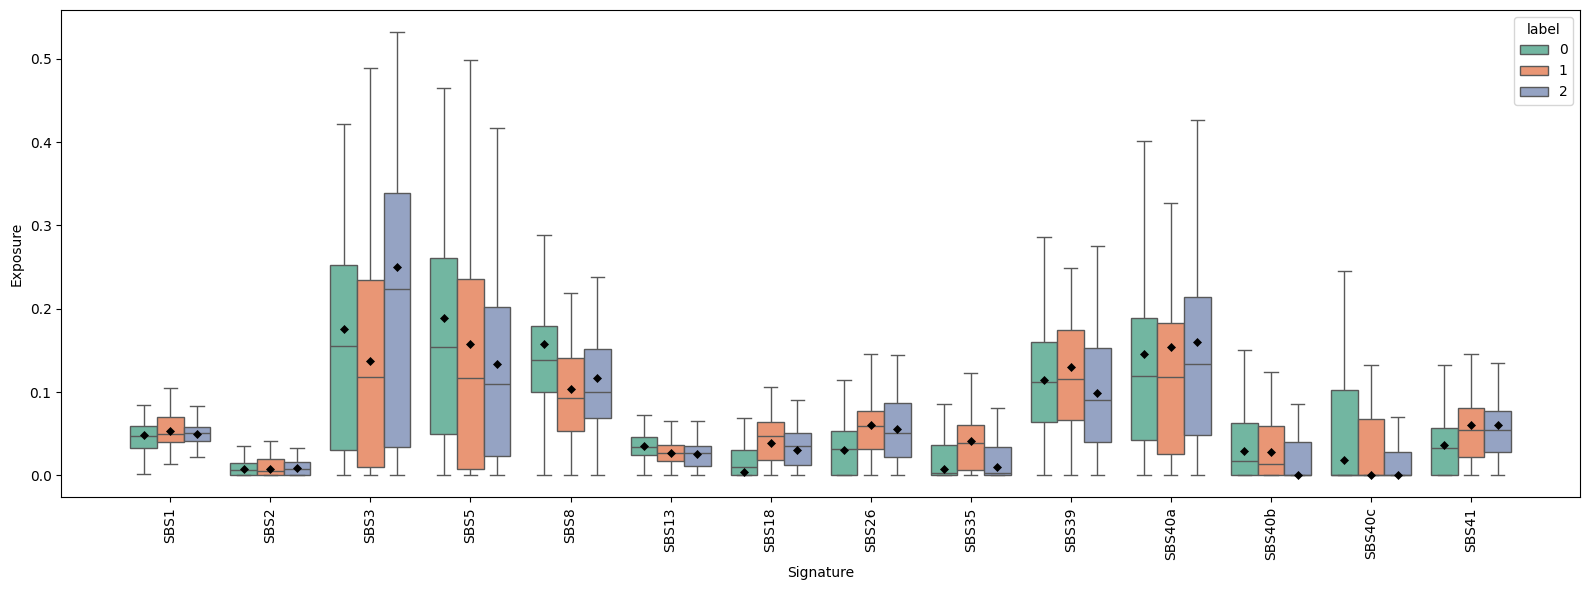

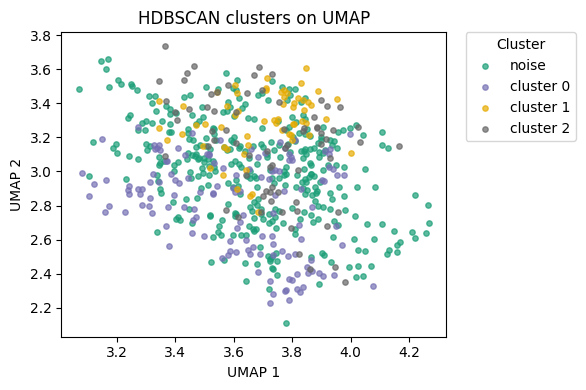

Loaded 615 cells.
Mutations per cell:
	min:  80
	mean: 372
	max:  722
Silhouette: 0.2787
DBCV: 0.2567


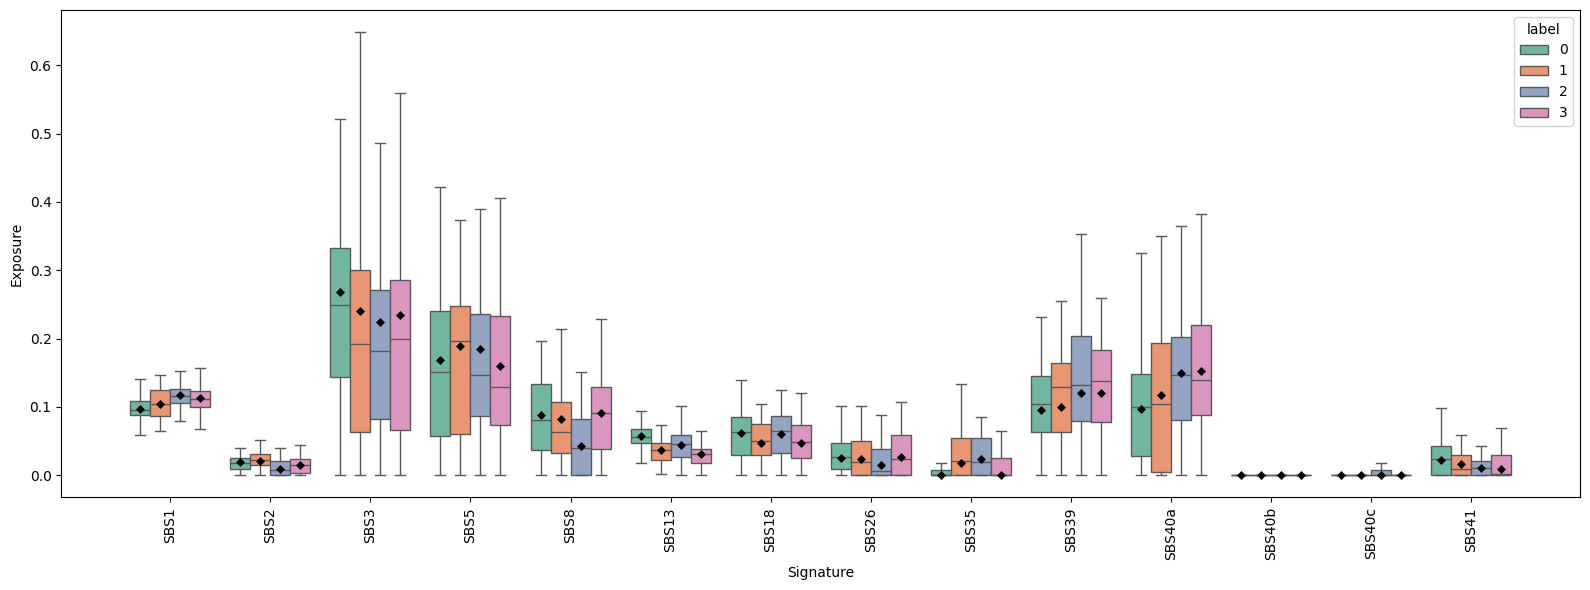

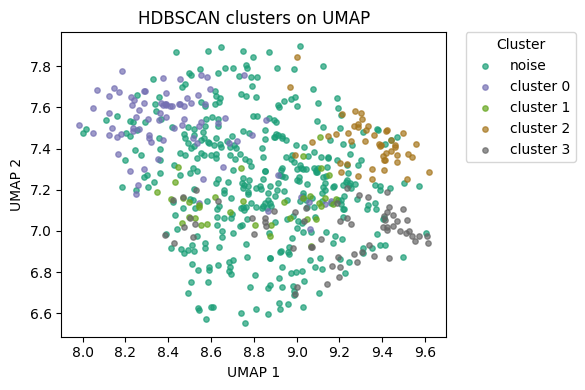

Loaded 643 cells.
Mutations per cell:
	min:  75
	mean: 462
	max:  1338
Silhouette: 0.3143
DBCV: 0.2401


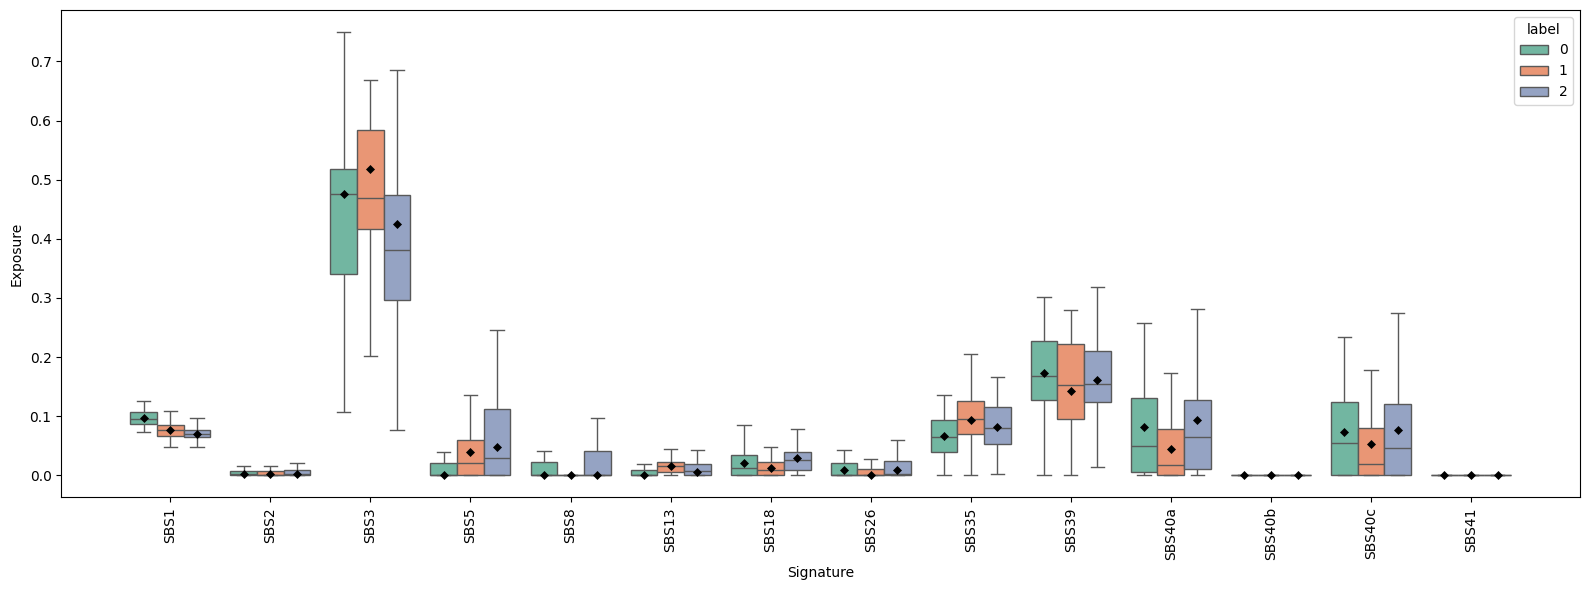

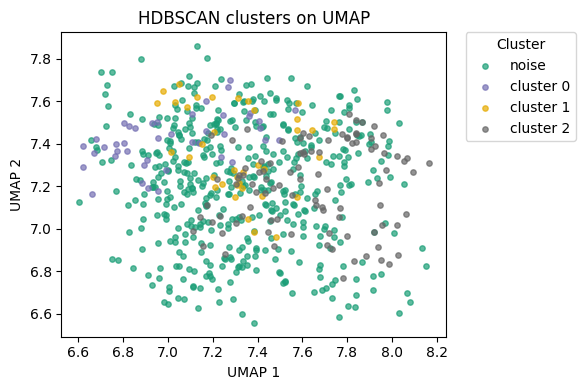

Loaded 649 cells.
Mutations per cell:
	min:  81
	mean: 398
	max:  888
Silhouette: 0.1311
DBCV: 0.0092


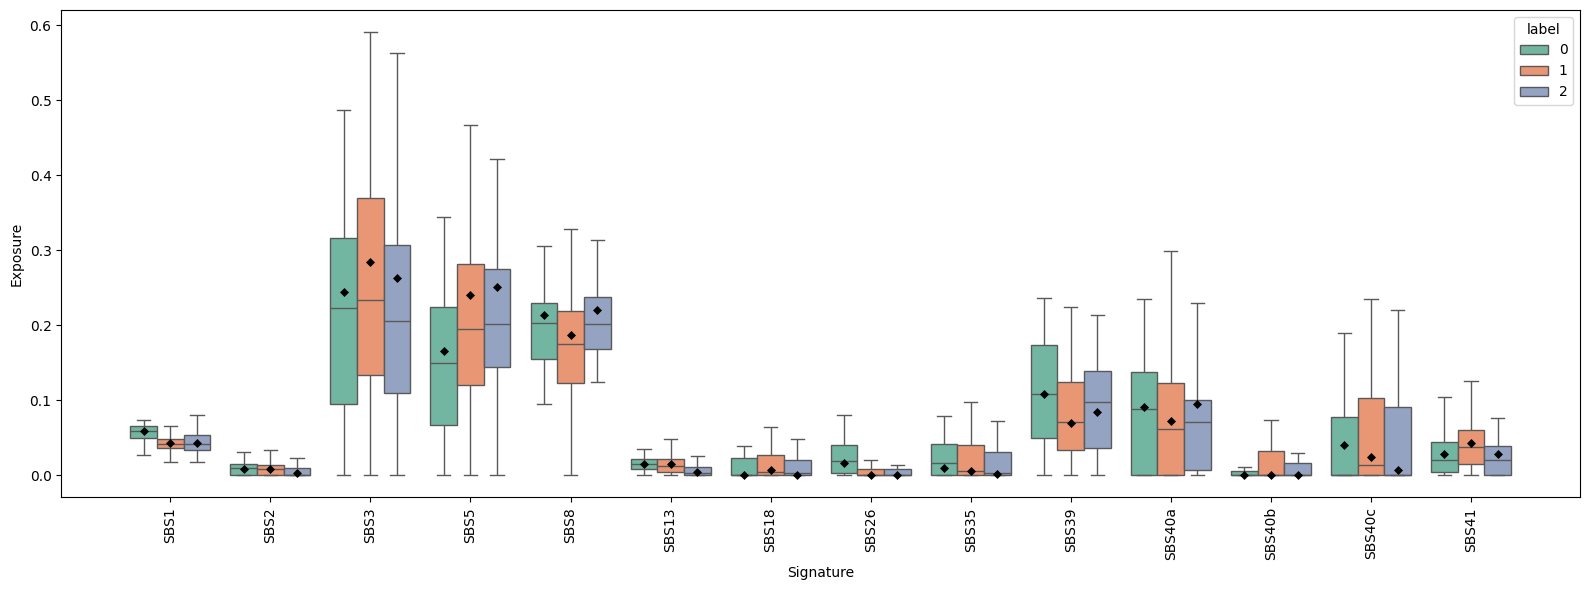

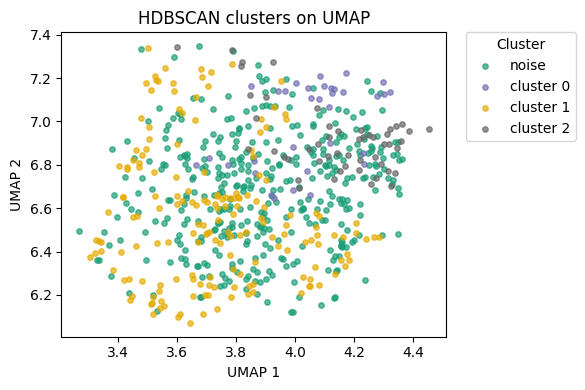

Loaded 632 cells.
Mutations per cell:
	min:  51
	mean: 232
	max:  920
Silhouette: 0.3055
DBCV: 0.0628


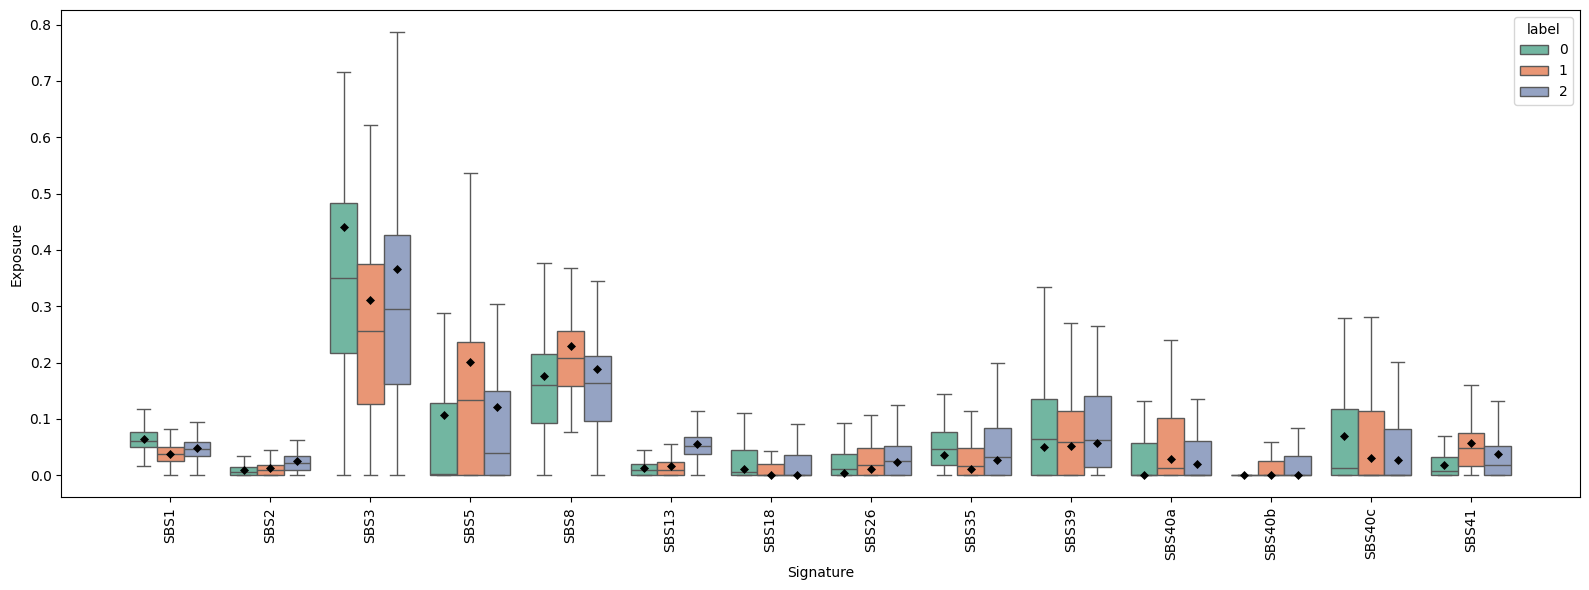

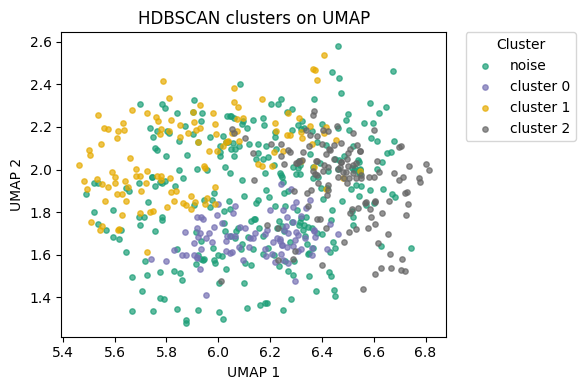

Loaded 760 cells.
Mutations per cell:
	min:  52
	mean: 250
	max:  728
Silhouette: 0.4411
DBCV: 0.4623


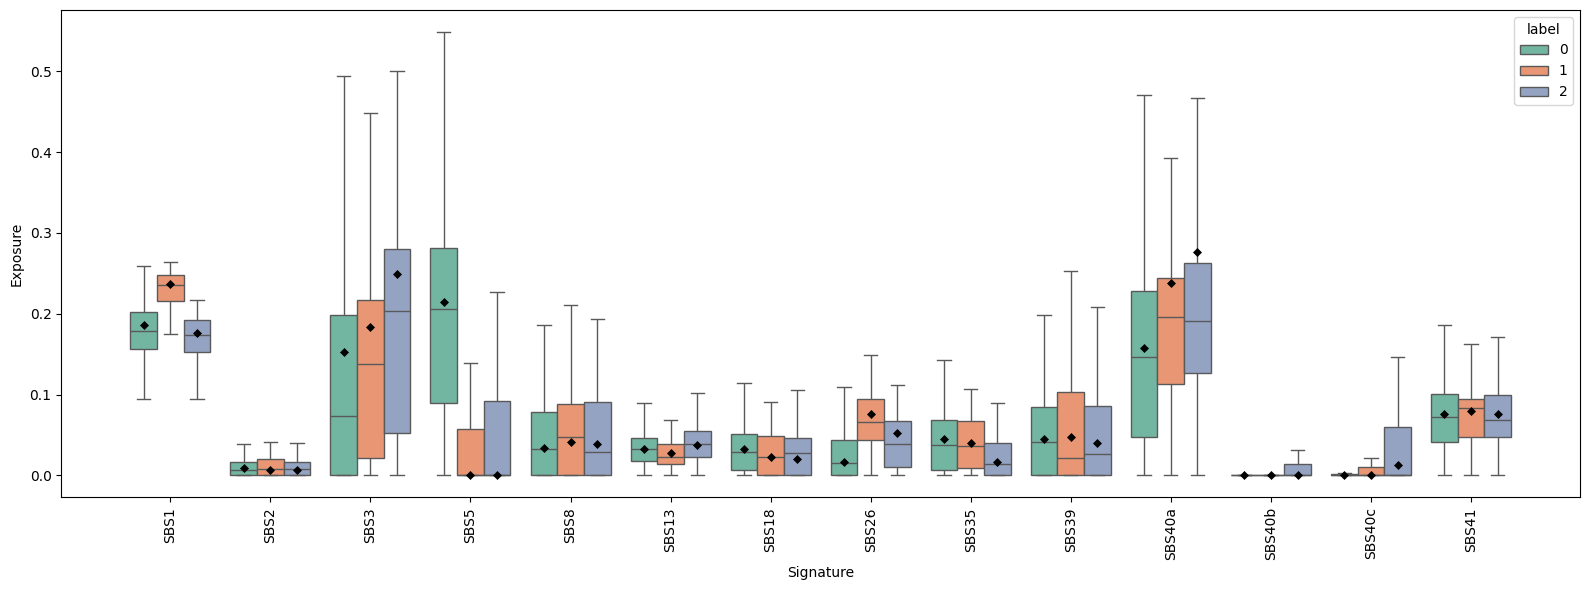

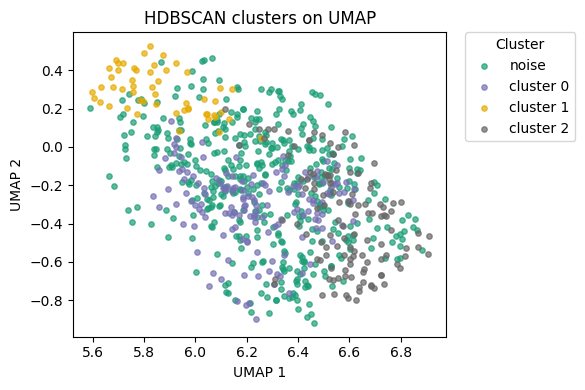

Loaded 892 cells.
Mutations per cell:
	min:  106
	mean: 775
	max:  2595
Silhouette: 0.1520
DBCV: 0.1166


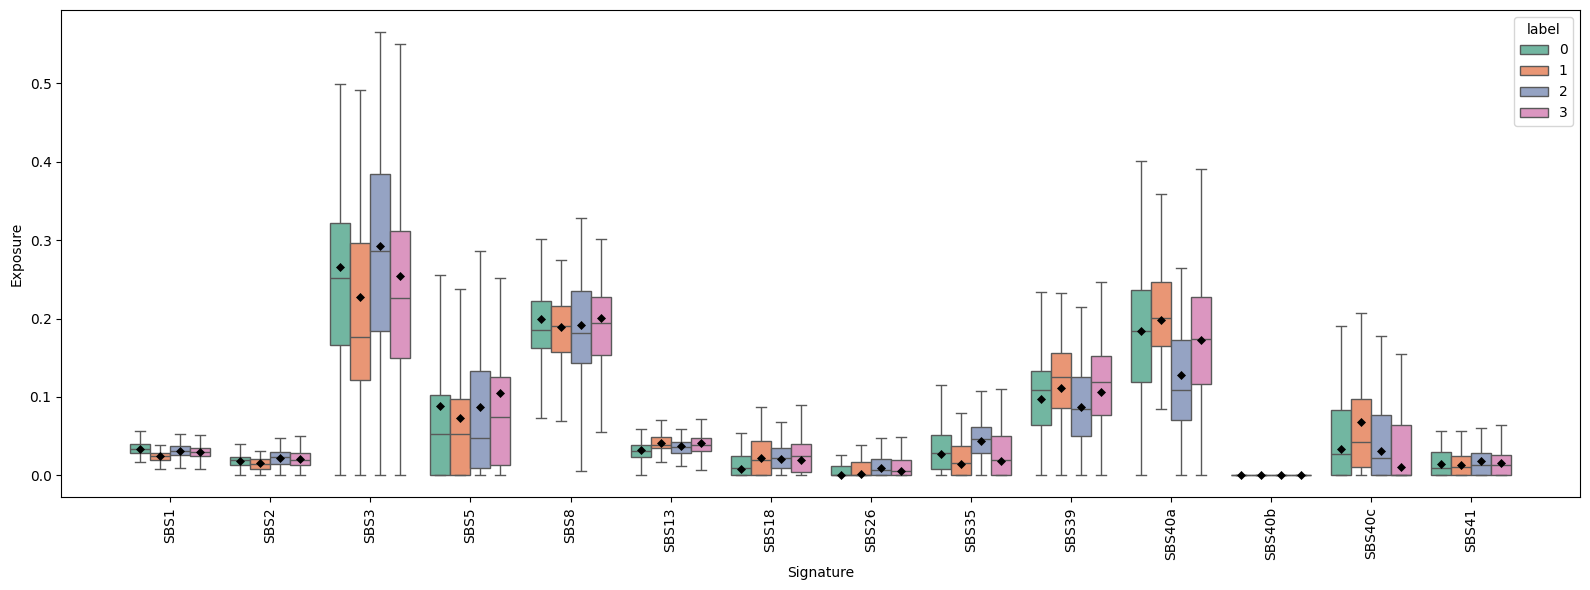

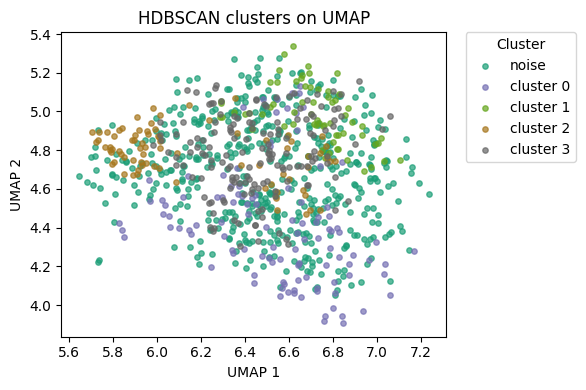

Loaded 895 cells.
Mutations per cell:
	min:  57
	mean: 263
	max:  545
Silhouette: 0.1565
DBCV: 0.1669


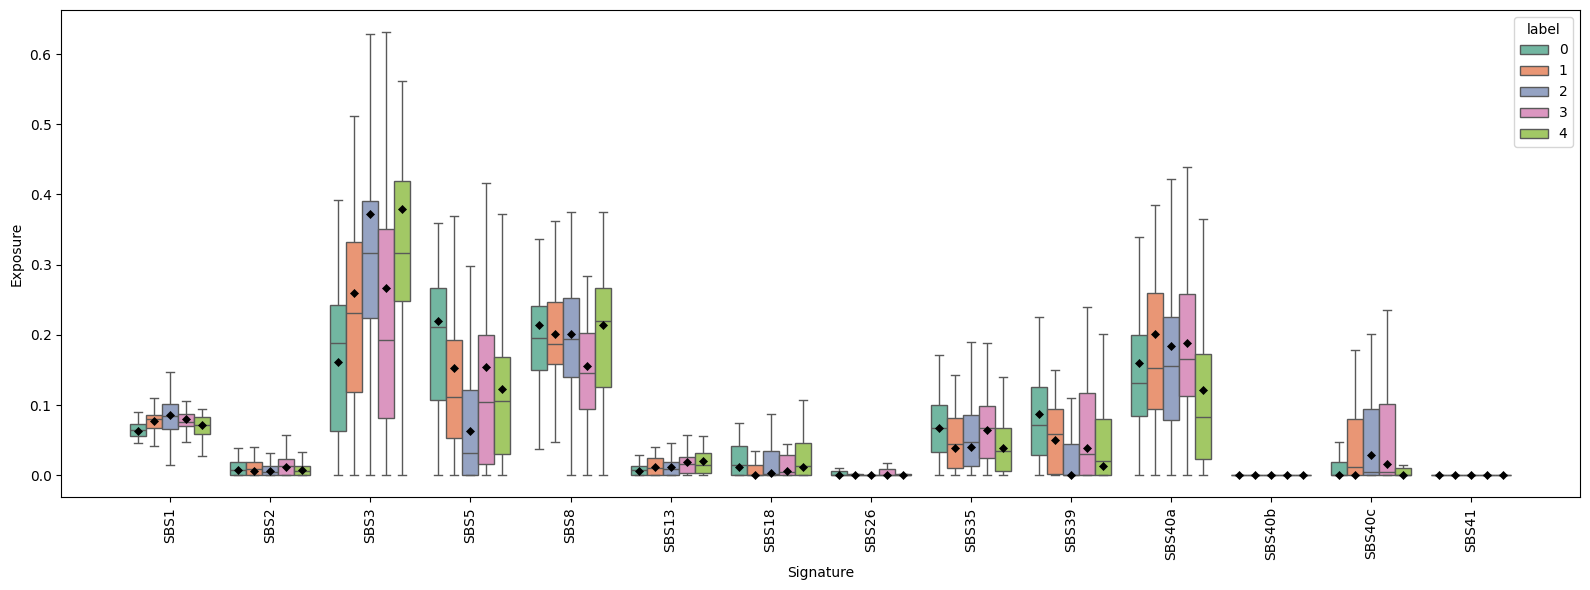

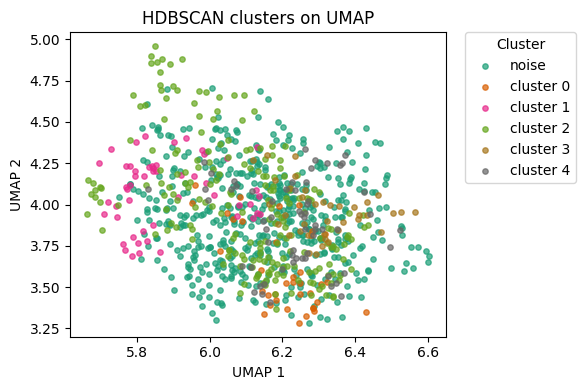

Loaded 962 cells.
Mutations per cell:
	min:  51
	mean: 189
	max:  414
Silhouette: 0.2944
DBCV: 0.1271


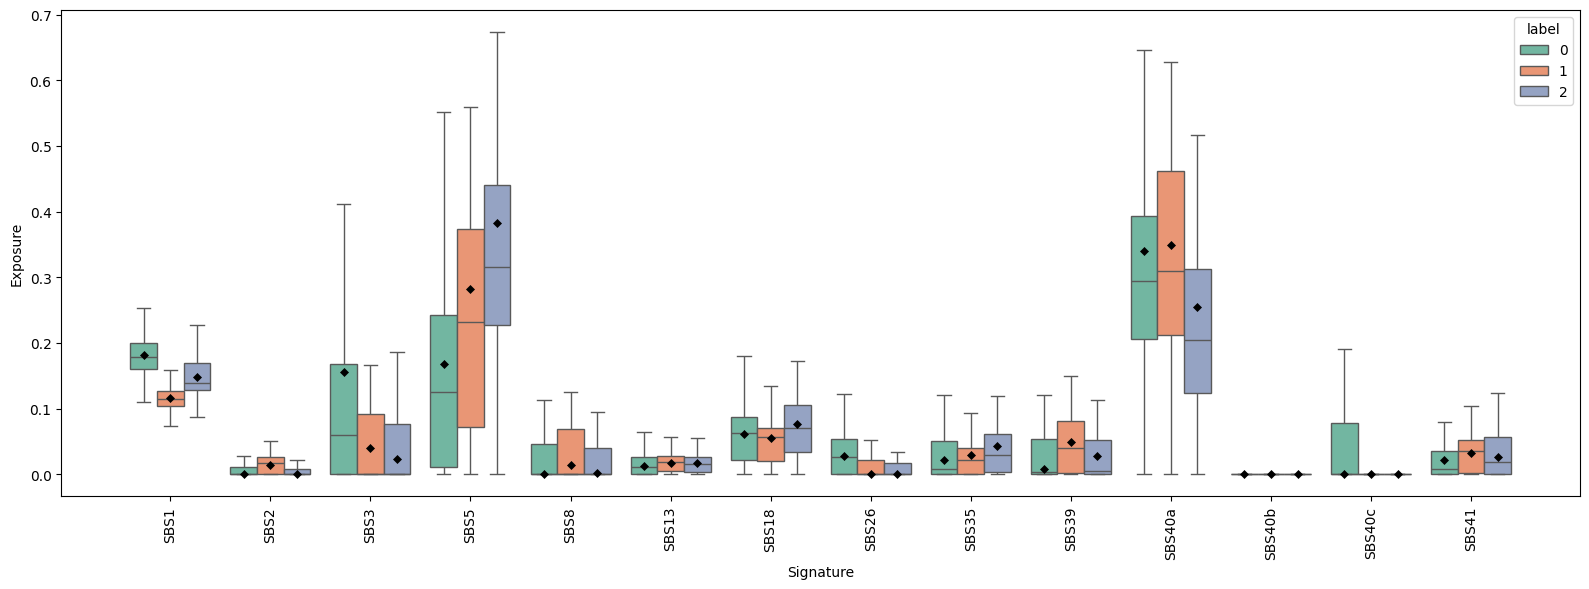

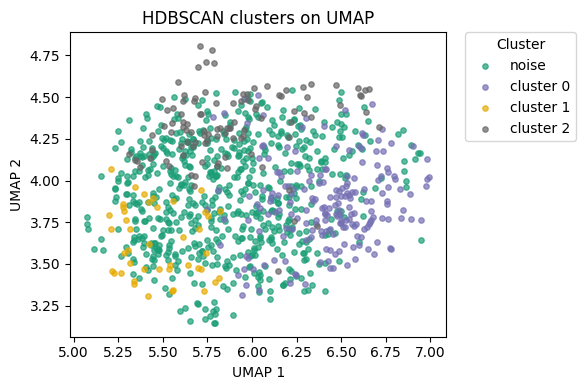

Loaded 97 cells.
Mutations per cell:
	min:  263
	mean: 1005
	max:  1707
Could not compute scores (too few clusters).


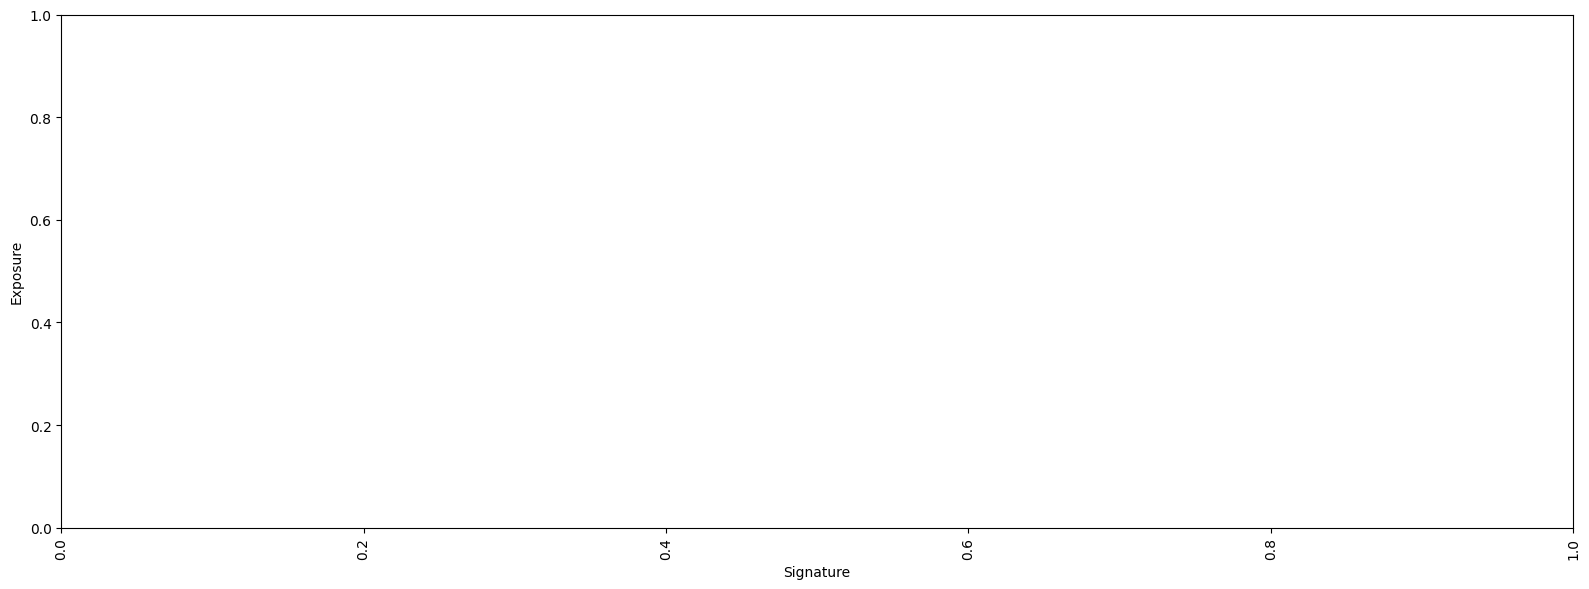

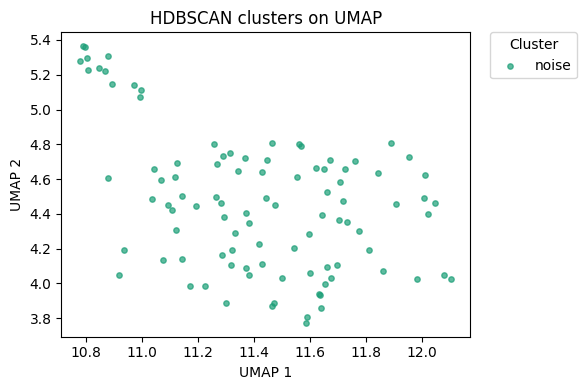

Error processing 97x21882: Need at least two groups in stats.kruskal()


In [60]:
for dim in dims:
    try:
        FILEPATH = os.path.abspath(os.path.join(os.getcwd(), f'../../data/mcpherson2025ongoing/mcpherson2025ongoing-OV{dim}.csv'))
        Y = ScUnit(FILEPATH, min_mutations=50)
        Y.umap().hdbscan().plot_exposures(signatures=cosmic.loc[ovary_sigs].T)
        Y.umap().hdbscan().plot_embedding()

        labels = Y.umap().hdbscan().get_labels()
        exposures = Y.deconv(signatures=cosmic.loc[ovary_sigs].T)
        test_signature_exposures(exposures, labels)
    except Exception as e:
        print(f"Error processing {dim}: {e}")

In [7]:
df['sbs'] = df.progress_apply(get_sbs, axis=1, args=(genome, chr_id))

  0%|          | 0/182235 [00:00<?, ?it/s]

186.90769230769232